 ══════════════════════════════════════════════════════════════════════
## VISIÓN POR COMPUTADORA — Tecnicatura Universitaria en IA (UNR - FCEIA)
# **TRABAJO PRÁCTICO N1**
* Parte 1: dataset y preprocesamiento*

**Integrantes:**
* Bartomioli, Ornella
* Vera, Sol Nahir

 ══════════════════════════════════════════════════════════════════════

## 0. Configuración inicial


Importamos las librerías y fijamos una semilla global para que los resultados sean reproducibles

In [ ]:
!pip install -q insightface onnxruntime albumentations scikit-learn pandas matplotlib tqdm opencv-python-headless

import os
import sys
import json
import random
import tarfile
import urllib.request
import warnings
from collections import Counter
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

warnings.filterwarnings('ignore')

print(f'OpenCV: {cv2.__version__} | NumPy: {np.__version__} | Pandas: {pd.__version__}')

OpenCV: 4.14.0 | NumPy: 2.1.3 | Pandas: 2.2.3


In [ ]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

In [ ]:
#── Dónde guardamos los datos ─
# En Colab usamos Google Drive para que los datos (y los splits) sobrevivan entre sesiones
# y la notebook 2 los pueda reutilizar. En local usamos ./data (está en el .gitignore).
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = Path('/content/drive/MyDrive/tp1_reconocimiento_facial')
else:
    BASE_DIR = Path('.')

DATA_DIR = Path(os.environ.get('TP1_DATA_DIR', BASE_DIR / 'data'))
ALIGNED_DIR = DATA_DIR / 'aligned'      # recortes alineados 112x112
SPLITS_DIR = DATA_DIR / 'splits'        # CSV de splits para la notebook 2
for d in (DATA_DIR, ALIGNED_DIR, SPLITS_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ── Pipeline facial (se replican en el .env de la app) ───────────────────────
FACE_SIZE = 112                  # .env: FACE_SIZE
DET_SCORE_THRESHOLD = 0.5        # .env: DET_SCORE_THRESHOLD
DET_INPUT_SIZE = (640, 640)      # .env: DET_INPUT_SIZE
MIN_FACE_SIZE = 40               # .env: MIN_FACE_SIZE  (lado mínimo del bbox, en px)

# ── Selección de identidades ─────────────────────────────────────────────────
MIN_IMGS_CARGA = 10              # mínimo de imágenes por identidad para entrar al pipeline
MIN_IMGS_FINAL = 10              # mínimo de imágenes por identidad DESPUÉS de limpiar
MAX_IMGS_POR_PERSONA = 50        # tope por identidad (mitiga el desbalance)

# ── Reglas de calidad ────────────────────────────────────────────────────────
AMBIGUO_AREA_RATIO = 0.5         # 2do rostro con >= 50% del área del principal => imagen ambigua
BLUR_PERCENTIL = 3               # descartamos el 3% más borroso (varianza del Laplaciano)
BRILLO_MIN, BRILLO_MAX = 45, 210 # brillo medio (0-255) fuera de este rango => exposición extrema
CONTRASTE_MIN = 25               # desvío estándar del brillo mínimo
DHASH_MAX_HAMMING = 4            # <= 4 bits de 64 de diferencia => casi-duplicado
SIM_DUPLICADO = 0.95             # similitud coseno entre embeddings => casi-duplicado
SIM_OUTLIER_PROPIA = 0.30        # similitud con el centroide de su propia clase (leave-one-out)

# ── Splits ───────────────────────────────────────────────────────────────────
PROP_IDS = (0.70, 0.15, 0.15)    # identidades: train / val_open / test_open
PROP_IMGS = (0.70, 0.15, 0.15)   # imágenes de las identidades de train: train / val / test_closed

print(f'Datos en: {DATA_DIR.resolve()}')
print(f'Semilla: {SEED} | FACE_SIZE: {FACE_SIZE} | Colab: {IN_COLAB}')

Mounted at /content/drive
Datos en: /content/drive/MyDrive/tp1_reconocimiento_facial/data
Semilla: 42 | FACE_SIZE: 112 | Colab: True


2. Dataset

## 1.1 Elección y justificación

Nuestro sistema tiene que **reconocer personas que se registran después del entrenamiento** (`/insert`).
Eso significa que el modelo se evalúa en un escenario **open-set**: identidades que nunca vio.
Para poder armar un split *por identidad* (y que igual queden identidades para entrenar) necesitamos **muchas identidades con varias imágenes cada una**.

| Dataset | Identidades / imágenes | Pro | Contra para este TP |
|---|---|---|---|
| **LFW** | ~5.700 / ~13.000 | Estándar de verificación; descarga directa sin cuenta; **ya lo usamos en clase** | Muy desbalanceado: la mayoría tiene 1 sola imagen |
| Pins Face Recognition | ~105 / ~17.000 | Muchas imágenes por persona | Requiere cuenta de Kaggle; pocas identidades para un split open-set; licencia a verificar |
| CelebA | ~10.000 / ~200.000 | Gran variedad | Pesado; hay que bajar un subconjunto |
| CASIA-WebFace | ~10.000 / ~490.000 | Estándar de entrenamiento | Pesado; etiquetas con ruido; acceso con restricciones |
| Dataset propio | — | Caso de uso real | Pocas identidades; requiere consentimiento de cada persona |

**Elegimos LFW** porque:
1. Tiene **miles de identidades**: filtrando las que tienen suficientes fotos nos quedan cientos, alcanza para un split open-set.
2. Es **reproducible**: cualquiera lo baja de la fuente oficial sin credenciales.
3. Es el **benchmark de referencia**: nuestros números se pueden comparar con la literatura y con lo visto en clase.
4. Son fotos *in the wild* (no de estudio): pose, luz y expresión varían.

Usamos las imágenes **originales** (`lfw.tgz`) y **no** la versión *funneled*, que ya viene pre-alineada.
Así la alineación que hacemos nosotros tiene un efecto real y se parece más a lo que le va a llegar a la app.

## 1.2 Limitaciones (que hay que tener presentes al leer los resultados)

- **Sesgo demográfico:** LFW está compuesto principalmente por figuras públicas de noticias de ~2002-2005. Estudios sobre el dataset reportan una gran mayoría de varones y de personas de piel clara. Un modelo ajustado acá puede rendir peor en otros grupos.
- **Sesgo frontal:** las imágenes se recolectaron donde el detector de Viola-Jones encontró una cara, así que hay pocos perfiles extremos.
- **Desbalance severo:** unas pocas personas (políticos muy fotografiados) concentran cientos de imágenes; la gran mayoría tiene una o dos.
- **Poco volumen para una CNN desde cero:** después de filtrar y limpiar tenemos pocos miles de imágenes. Es poco comparado con los cientos de miles que se usan para entrenar modelos de estado del arte. Lo vamos a discutir en la notebook 2.
- **Licencia:** LFW no trae una licencia permisiva estándar. Se distribuye para investigación y evaluación académica y las fotos conservan el copyright de las fuentes originales. **Uso académico, sin redistribuir las imágenes** (el `.gitignore` ya excluye `data/*`).


## 1.3 Descarga

Bajamos `lfw.tgz` del sitio oficial (UMass) y lo descomprimimos en `data/lfw/`. La celda es idempotente: si ya está, no vuelve a bajarlo.

> Si el sitio de UMass no responde, una alternativa es `sklearn.datasets.fetch_lfw_people(funneled=False)`, que baja el mismo dataset desde un espejo
> y lo deja en `sklearn.datasets.get_data_home()/lfw_home/lfw`. Apuntá `LFW_DIR` a esa carpeta.

In [ ]:
LFW_URL = 'https://vis-www.cs.umass.edu/lfw/lfw.tgz'
LFW_DIR = DATA_DIR / 'lfw'

if LFW_DIR.exists() and any(LFW_DIR.iterdir()):
    print(f'ya existe  -> {LFW_DIR}')
else:
    tgz = DATA_DIR / 'lfw.tgz'
    if not tgz.exists():
        print('Descargando lfw.tgz (~175 MB, puede tardar unos minutos)...')
        req = urllib.request.Request(LFW_URL, headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(req, timeout=60) as r, open(tgz, 'wb') as f:
            while True:
                bloque = r.read(1 << 20)
                if not bloque:
                    break
                f.write(bloque)
    print('Descomprimiendo...')
    with tarfile.open(tgz) as t:
        t.extractall(DATA_DIR, filter='data')   # crea DATA_DIR/lfw
    print(f'listo -> {LFW_DIR}')

ya existe  -> /content/drive/MyDrive/tp1_reconocimiento_facial/data/lfw


In [ ]:
import os
import shutil
from pathlib import Path
from sklearn.datasets import fetch_lfw_people, get_data_home

LFW_DIR = DATA_DIR / 'lfw'
tgz_invalido = DATA_DIR / 'lfw.tgz'

# Borrar el archivo vacío/corrupto si quedó guardado
if tgz_invalido.exists() and tgz_invalido.stat().st_size < 10_000_000:
    print("Eliminando archivo tgz corrupto...")
    tgz_invalido.unlink()

if LFW_DIR.exists() and any(LFW_DIR.iterdir()):
    print(f'Ya existe -> {LFW_DIR}')
else:
    print("Descargando LFW crudo mediante scikit-learn...")
    # Descarga la versión sin pre-alinear (funneled=False) en el directorio local de sklearn
    _ = fetch_lfw_people(funneled=False, resize=None, color=True)

    # Ruta donde scikit-learn guarda las carpetas de LFW
    sklearn_lfw = Path(get_data_home()) / 'lfw_home' / 'lfw'

    print(f"Copiando a {LFW_DIR}...")
    shutil.copytree(sklearn_lfw, LFW_DIR, dirs_exist_ok=True)
    print(f"Listo -> {LFW_DIR}")

Ya existe -> /content/drive/MyDrive/tp1_reconocimiento_facial/data/lfw


In [ ]:
# Listamos TODAS las imágenes de LFW: una fila por imagen, con ruta relativa a DATA_DIR
# (así los CSV que guardamos después son portables entre tu compu y Colab)
EXTENSIONES = {'.jpg', '.jpeg', '.png', '.bmp'}

registros = []
for persona_dir in sorted(LFW_DIR.iterdir()):
    if not persona_dir.is_dir():
        continue
    for f in sorted(persona_dir.iterdir()):
        if f.suffix.lower() in EXTENSIONES:
            registros.append({'identidad': persona_dir.name, 'ruta_raw': str(f.relative_to(DATA_DIR))})

df_lfw = pd.DataFrame(registros)
print(f'LFW completo: {len(df_lfw):,} imágenes | {df_lfw.identidad.nunique():,} identidades')
df_lfw.head()

LFW completo: 13,233 imágenes | 5,749 identidades


,identidad,ruta_raw
0,AJ_Cook,lfw/AJ_Cook/AJ_Cook_0001.jpg
1,AJ_Lamas,lfw/AJ_Lamas/AJ_Lamas_0001.jpg
2,Aaron_Eckhart,lfw/Aaron_Eckhart/Aaron_Eckhart_0001.jpg
3,Aaron_Guiel,lfw/Aaron_Guiel/Aaron_Guiel_0001.jpg
4,Aaron_Patterson,lfw/Aaron_Patterson/Aaron_Patterson_0001.jpg


3.Análisis exploratorio (EDA)

## 2.1 Imágenes por identidad y desbalance de clases

Primero miramos **todo LFW** para entender el desbalance. Después decidimos con qué identidades nos quedamos.

Estadísticas de imágenes por identidad (LFW completo):
identidades              5749.00
imágenes                13233.00
media                       2.30
mediana                     1.00
mínimo                      1.00
máximo                    530.00
% con 1 sola imagen        70.78
% con >= 10 imágenes        2.75


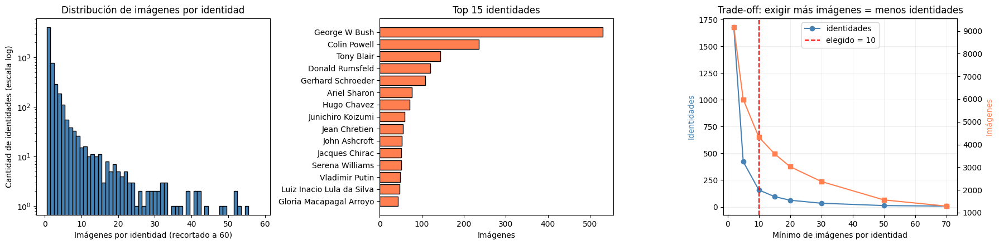


Umbral mínimo -> identidades / imágenes que sobreviven:
  >=  2 imágenes: 1,680 identidades |  9,164 imágenes
  >=  5 imágenes:   423 identidades |  5,985 imágenes
  >= 10 imágenes:   158 identidades |  4,324 imágenes
  >= 15 imágenes:    96 identidades |  3,595 imágenes
  >= 20 imágenes:    62 identidades |  3,023 imágenes
  >= 30 imágenes:    34 identidades |  2,370 imágenes
  >= 50 imágenes:    12 identidades |  1,560 imágenes
  >= 70 imágenes:     7 identidades |  1,288 imágenes


In [ ]:
conteo = df_lfw.groupby('identidad').size().sort_values(ascending=False)

stats = pd.Series({
    'identidades': len(conteo),
    'imágenes': conteo.sum(),
    'media': conteo.mean(),
    'mediana': conteo.median(),
    'mínimo': conteo.min(),
    'máximo': conteo.max(),
    '% con 1 sola imagen': 100 * (conteo == 1).mean(),
    '% con >= 10 imágenes': 100 * (conteo >= 10).mean(),
})
print('Estadísticas de imágenes por identidad (LFW completo):')
print(stats.round(2).to_string())

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# Histograma con eje log: la cola larga se ve mejor
axes[0].hist(conteo.values, bins=np.arange(1, 60) - 0.5, color='steelblue', edgecolor='black')
axes[0].set_yscale('log')
axes[0].set_xlabel('Imágenes por identidad (recortado a 60)')
axes[0].set_ylabel('Cantidad de identidades (escala log)')
axes[0].set_title('Distribución de imágenes por identidad')

# Las 15 identidades con más imágenes
top = conteo.head(15)
axes[1].barh([n.replace('_', ' ') for n in top.index][::-1], top.values[::-1], color='coral', edgecolor='black')
axes[1].set_xlabel('Imágenes')
axes[1].set_title('Top 15 identidades')

# Trade-off del umbral mínimo de imágenes por identidad
umbrales = [2, 5, 10, 15, 20, 30, 50, 70]
n_ids = [(conteo >= u).sum() for u in umbrales]
n_imgs = [conteo[conteo >= u].sum() for u in umbrales]
ax2 = axes[2]
ax2.plot(umbrales, n_ids, 'o-', color='steelblue', label='identidades')
ax2.set_xlabel('Mínimo de imágenes por identidad')
ax2.set_ylabel('Identidades', color='steelblue')
ax2.axvline(MIN_IMGS_CARGA, color='red', linestyle='--', label=f'elegido = {MIN_IMGS_CARGA}')
ax3 = ax2.twinx()
ax3.plot(umbrales, n_imgs, 's-', color='coral')
ax3.set_ylabel('Imágenes', color='coral')
ax2.set_title('Trade-off: exigir más imágenes = menos identidades')
ax2.legend(loc='upper center')
ax2.grid(alpha=0.2)

plt.tight_layout()
plt.show()

print('\nUmbral mínimo -> identidades / imágenes que sobreviven:')
for u, a, b in zip(umbrales, n_ids, n_imgs):
    print(f'  >= {u:>2} imágenes: {a:>5,} identidades | {b:>6,} imágenes')

### Decisión: ¿con qué identidades nos quedamos?

El enunciado sugiere un mínimo de **10–20 imágenes por persona**. La curva muestra el trade-off:
subir el mínimo da más imágenes por persona pero **se pierden identidades rápidamente**, y las identidades son lo que más necesitamos
para tener un split open-set con suficientes personas nuevas en test.

Usamos **`MIN_IMGS_CARGA = 10`**: con 10 imágenes por persona alcanza para partir en train/val/test dentro de cada identidad,
y para armar galería + consultas en la notebook 2. Después de la limpieza (sección 4) volvemos a exigir `MIN_IMGS_FINAL = 10`.

In [ ]:
ids_sel = conteo[conteo >= MIN_IMGS_CARGA].index
df = df_lfw[df_lfw.identidad.isin(ids_sel)].reset_index(drop=True)

# Embudo: vamos anotando cuántas identidades / imágenes quedan en cada etapa (se usa en el resumen final)
EMBUDO = []
def registrar_embudo(etapa, d):
    EMBUDO.append({'etapa': etapa, 'identidades': d.identidad.nunique(), 'imágenes': len(d)})

registrar_embudo('LFW completo', df_lfw)
registrar_embudo(f'Identidades con >= {MIN_IMGS_CARGA} imágenes', df)

print(f'Nos quedamos con {df.identidad.nunique()} identidades y {len(df):,} imágenes '
      f'({100 * len(df) / len(df_lfw):.1f}% de las imágenes de LFW)')

Nos quedamos con 158 identidades y 4,324 imágenes (32.7% de las imágenes de LFW)


## 2.2 Resoluciones, canales y formato

Recorremos todas las imágenes seleccionadas y medimos: tamaño, canales, si abren bien y si son **blanco y negro**
(un caso típico que forma sub-clusters). De paso calculamos brillo y contraste, que usamos en 2.4.

In [ ]:
def leer_bgr(ruta_rel, flags=cv2.IMREAD_COLOR):
    """Lee una imagen (ruta relativa a DATA_DIR) en BGR uint8, igual que lo hará la app. None si no abre."""
    return cv2.imread(str(DATA_DIR / ruta_rel), flags)

filas = []
for ruta in tqdm(df.ruta_raw, desc='EDA: leyendo imágenes'):
    img = leer_bgr(ruta, cv2.IMREAD_UNCHANGED)       # UNCHANGED: así vemos si el archivo es 1 canal
    if img is None:
        filas.append({'abre': False})
        continue
    canales = 1 if img.ndim == 2 else img.shape[2]
    if canales == 1:
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    b, g, r = [img[..., i].astype(np.int16) for i in range(3)]
    # "Blanco y negro" aunque el archivo tenga 3 canales: los canales casi no difieren entre sí
    dif_canales = (np.abs(b - g).mean() + np.abs(g - r).mean()) / 2
    filas.append({
        'abre': True, 'alto': img.shape[0], 'ancho': img.shape[1], 'canales_archivo': canales,
        'es_bn': bool(canales == 1 or dif_canales < 3),
        'brillo': float(gris.mean()), 'contraste': float(gris.std()),
    })

df = pd.concat([df, pd.DataFrame(filas)], axis=1)
df['ext'] = df.ruta_raw.str.extract(r'(\.\w+)$')[0].str.lower()

print(f'Imágenes que NO abren (corruptas): {(~df.abre).sum()}')
print(f'\nResoluciones (alto x ancho):')
print(df.groupby(['alto', 'ancho']).size().to_string())
print(f'\nCanales en el archivo: {df.canales_archivo.value_counts().to_dict()}')
print(f'Extensiones: {df.ext.value_counts().to_dict()}')
print(f'Imágenes en blanco y negro: {df.es_bn.sum()} ({100 * df.es_bn.mean():.1f}%)')

EDA: leyendo imágenes:   0%|          | 0/4324 [00:00<?, ?it/s]

Imágenes que NO abren (corruptas): 0

Resoluciones (alto x ancho):
alto  ancho
250   250      4324

Canales en el archivo: {3: 4324}
Extensiones: {'.jpg': 4324}
Imágenes en blanco y negro: 1 (0.0%)


 **Nota sobre las resoluciones:** LFW distribuye todas las imágenes con el mismo tamaño fijo, así que la distribución de ancho × alto es trivial (un solo valor).
> Lo que **sí** varía es el **tamaño del rostro dentro de la imagen**, que medimos con el detector en la sección 3 y 4.
> Tampoco esperamos archivos corruptos porque LFW está curado; la regla igual queda implementada en la sección 4 para cuando se use un dataset propio.

## 2.3 Muestra visual

Grilla con varias imágenes por identidad, elegidas al azar, y después los **casos difíciles**: los más oscuros, los más claros, los de menor contraste y los blanco y negro.

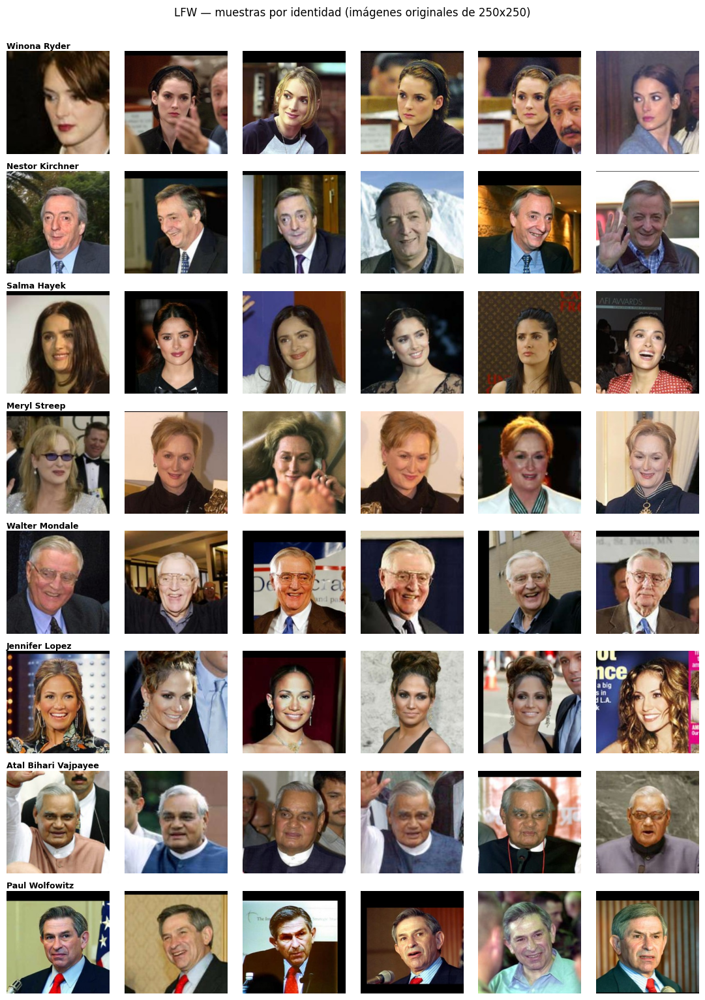

In [ ]:
def mostrar_grilla(imgs_bgr, titulos=None, ncols=6, titulo='', lado=1.9, fontsize=8):
    """Muestra una lista de imágenes BGR en una grilla (convierte a RGB solo para matplotlib)."""
    n = len(imgs_bgr)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * lado, nrows * lado * 1.1), squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis('off')
        if i < n:
            ax.imshow(cv2.cvtColor(imgs_bgr[i], cv2.COLOR_BGR2RGB))
            if titulos is not None:
                ax.set_title(titulos[i], fontsize=fontsize)
    if titulo:
        plt.suptitle(titulo, fontsize=11, y=1.0)
    plt.tight_layout()
    plt.show()

# 8 identidades al azar x 6 imágenes cada una
rng = np.random.default_rng(SEED)
ids_muestra = rng.choice(df.identidad.unique(), size=8, replace=False)

fig, axes = plt.subplots(len(ids_muestra), 6, figsize=(11, 1.9 * len(ids_muestra)))
for fila, nombre in enumerate(ids_muestra):
    rutas = df[df.identidad == nombre].ruta_raw.values
    elegidas = rng.choice(rutas, size=min(6, len(rutas)), replace=False)
    for col in range(6):
        axes[fila, col].axis('off')
        if col < len(elegidas):
            axes[fila, col].imshow(cv2.cvtColor(leer_bgr(elegidas[col]), cv2.COLOR_BGR2RGB))
    axes[fila, 0].set_title(nombre.replace('_', ' '), fontsize=9, fontweight='bold', loc='left', pad=3)
plt.suptitle('LFW — muestras por identidad (imágenes originales de 250x250)', y=1.005)
plt.tight_layout()
plt.show()

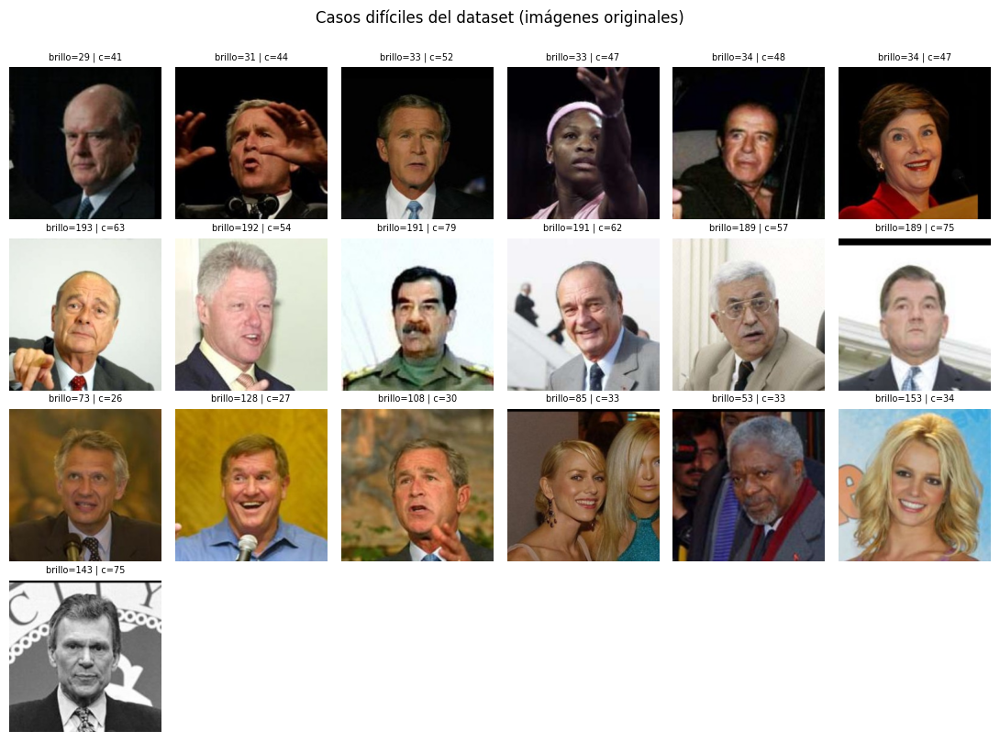

In [ ]:
# Casos difíciles: extremos de brillo y contraste, y blanco y negro
casos = {
    'Más oscuras': df.sort_values('brillo').head(6),
    'Más claras': df.sort_values('brillo', ascending=False).head(6),
    'Menor contraste': df.sort_values('contraste').head(6),
    'Blanco y negro': df[df.es_bn].head(6),
}

fig, axes = plt.subplots(len(casos), 6, figsize=(11, 2.0 * len(casos)))
for fila, (nombre_caso, sub) in enumerate(casos.items()):
    for col in range(6):
        axes[fila, col].axis('off')
        if col < len(sub):
            r = sub.iloc[col]
            axes[fila, col].imshow(cv2.cvtColor(leer_bgr(r.ruta_raw), cv2.COLOR_BGR2RGB))
            axes[fila, col].set_title(f'brillo={r.brillo:.0f} | c={r.contraste:.0f}', fontsize=7)
    axes[fila, 0].set_ylabel(nombre_caso, rotation=0, labelpad=55, va='center', fontweight='bold', fontsize=9)
plt.suptitle('Casos difíciles del dataset (imágenes originales)', y=1.005)
plt.tight_layout()
plt.show()

## 2.4 Variaciones: iluminación y contraste

El brillo medio y el desvío estándar del brillo son una medida simple (y objetiva) de la **iluminación**.
La pose, las oclusiones y la expresión las estudiamos con las landmarks del detector, después de la sección 3.

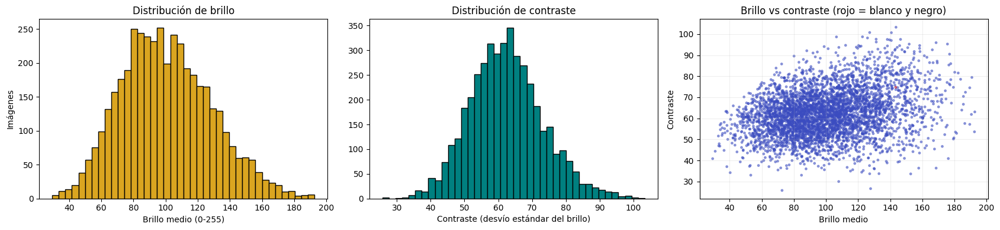

Brillo   — media: 100.6 | p5: 57.8 | p95: 150.4
Contraste — media: 62.4 | p5: 45.6 | p95: 81.3


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

axes[0].hist(df.brillo, bins=40, color='goldenrod', edgecolor='black')
axes[0].set_xlabel('Brillo medio (0-255)')
axes[0].set_ylabel('Imágenes')
axes[0].set_title('Distribución de brillo')

axes[1].hist(df.contraste, bins=40, color='teal', edgecolor='black')
axes[1].set_xlabel('Contraste (desvío estándar del brillo)')
axes[1].set_title('Distribución de contraste')

sc = axes[2].scatter(df.brillo, df.contraste, c=df.es_bn.astype(int), cmap='coolwarm', s=6, alpha=0.5)
axes[2].set_xlabel('Brillo medio')
axes[2].set_ylabel('Contraste')
axes[2].set_title('Brillo vs contraste (rojo = blanco y negro)')
axes[2].grid(alpha=0.2)

plt.tight_layout()
plt.show()

print(f'Brillo   — media: {df.brillo.mean():.1f} | p5: {df.brillo.quantile(0.05):.1f} | p95: {df.brillo.quantile(0.95):.1f}')
print(f'Contraste — media: {df.contraste.mean():.1f} | p5: {df.contraste.quantile(0.05):.1f} | p95: {df.contraste.quantile(0.95):.1f}')

### Observaciones del EDA

> ✍️ **Completar después de ejecutar** (2–4 líneas con lo que vean en los gráficos de arriba):
> - ¿Qué tan desbalanceado está? ¿Cuántas imágenes concentran las 15 identidades más grandes frente a la mediana?
> - ¿Qué porcentaje de imágenes es blanco y negro? ¿Y cuántas se ven muy oscuras o muy claras?
> - ¿Qué casos "difíciles" aparecen en la grilla (perfiles, anteojos, gorros, baja luz)?

# 3. DETECCIÓN Y ALINEACIÓN

Un modelo de reconocimiento facial espera **rostros recortados y alineados de forma consistente**: ojos a la misma altura, misma escala, misma posición de nariz y boca.
Si cada imagen llega con otra rotación y otro zoom, parte de la diferencia entre embeddings va a ser pose y encuadre en lugar de identidad.

## 3.1 Elección del detector

| Detector | Landmarks | Se ejecuta con | Comentario |
|---|---|---|---|
| Haar / Viola-Jones | No | OpenCV | Muy rápido pero poco robusto a pose e iluminación; sin landmarks no hay alineación |
| MTCNN (el de clase) | 5 | PyTorch (`facenet-pytorch`) | Funciona bien, pero obliga a depender de torch en la app; más lento |
| YuNet | 5 | OpenCV / ONNX | Liviano; buen candidato |
| **SCRFD (InsightFace)** | **5** | **ONNX** | **Elegido** |

**Elegimos SCRFD (`det_10g` del paquete `buffalo_l` de InsightFace)** por:
1. Devuelve **bbox + 5 landmarks** en una sola pasada, que es lo que necesita `align_face` y lo que dibuja el frontend.
2. Corre en **ONNX Runtime**: la app no necesita PyTorch para detectar.
3. Es de la **misma familia** que el reconocedor ArcFace (`w600k_r50`) que vamos a usar como Modelo B en la notebook 2: misma plantilla de alineación, mismo preprocesamiento.
4. `insightface.utils.face_align.norm_crop` es justamente la alineación recomendada en el enunciado.

## 3.2 Convenciones del pipeline (idénticas en la app)

| Aspecto | Convención |
|---|---|
| Imagen de entrada | `np.ndarray` **BGR uint8** (como la devuelve `cv2.imread`) |
| Caja | `(x1, y1, x2, y2)` en píxeles de la imagen original |
| Landmarks | Array `(5, 2)`: ojo izq, ojo der, nariz, comisura izq, comisura der |
| Alineación | Transformación de **similitud** (rotación + escala + traslación) de los 5 landmarks hacia la plantilla de referencia de ArcFace |
| Rostro alineado | **112×112, BGR uint8** (`FACE_SIZE`) |
| Embedding | Vector **normalizado L2** |

> En `face_service.py` los keypoints se devuelven **relativos a la caja** (`x - x1`, `y - y1`) porque el frontend les vuelve a sumar `(x1, y1)`.
> Dejamos la función `kps_relativos` ya escrita para no olvidarnos.

In [ ]:
from insightface.app import FaceAnalysis
from insightface.utils import face_align

# Cargamos SCRFD (detección) y ArcFace (reconocimiento) del paquete buffalo_l.
# Se descargan la primera vez a ~/.insightface/models/buffalo_l
app = FaceAnalysis(name='buffalo_l', allowed_modules=['detection', 'recognition'],
                   providers=['CPUExecutionProvider'])
app.prepare(ctx_id=-1, det_thresh=DET_SCORE_THRESHOLD, det_size=DET_INPUT_SIZE)

detector = app.det_model                 # SCRFD
reconocedor = app.models['recognition']  # ArcFace ResNet-50 (embedding de 512 dimensiones)

print(f'\nDetector: {type(detector).__name__} | Reconocedor: {type(reconocedor).__name__}')

download_path: /root/.insightface/models/buffalo_l


100%|██████████| 281857/281857 [00:04<00:00, 67321.49KB/s]



Detector: SCRFD | Reconocedor: ArcFaceONNX


## 3.3 Funciones del pipeline

Todo el pipeline queda encapsulado en funciones chicas y reutilizables. **Estas mismas funciones (o su equivalente) son las que van a `face_service.py`.**
Además de detectar y alinear, definimos medidas auxiliares (ángulo de roll, proxy de yaw, varianza del Laplaciano, hash perceptual) que usamos para el control de calidad.

In [ ]:
# ═════════════════════════════════════════════════════════════════════════════
#  PIPELINE REUTILIZABLE — es el mismo que debe usar face_service.py
# ═════════════════════════════════════════════════════════════════════════════

def detectar_rostros(img_bgr):
    """Detecta rostros. Entrada: imagen BGR uint8.
    Devuelve una lista de dicts {bbox (x1,y1,x2,y2), score, kps (5,2)} ordenada por score."""
    bboxes, kpss = detector.detect(img_bgr, max_num=0, metric='default')
    caras = []
    for i in range(len(bboxes)):
        caras.append({
            'bbox': bboxes[i, :4].astype(float),
            'score': float(bboxes[i, 4]),
            'kps': kpss[i].astype(float) if kpss is not None else None,
        })
    return sorted(caras, key=lambda c: -c['score'])


def area_bbox(bbox):
    x1, y1, x2, y2 = bbox
    return max(0.0, x2 - x1) * max(0.0, y2 - y1)


def elegir_rostro_principal(caras, shape):
    """Si hay varios rostros, nos quedamos con el más grande y más cercano al centro."""
    h, w = shape[:2]
    cx, cy = w / 2, h / 2
    diag = np.hypot(cx, cy)
    def puntaje(c):
        x1, y1, x2, y2 = c['bbox']
        dist = np.hypot((x1 + x2) / 2 - cx, (y1 + y2) / 2 - cy) / diag
        return area_bbox(c['bbox']) * (1 - dist)
    return max(caras, key=puntaje)


def alinear_rostro(img_bgr, kps, size=FACE_SIZE):
    """Alinea con los 5 landmarks (transformación de similitud hacia la plantilla ArcFace).
    Devuelve el rostro de size x size en BGR uint8."""
    return face_align.norm_crop(img_bgr, landmark=np.asarray(kps, dtype=np.float32), image_size=size)


def kps_relativos(kps, bbox):
    """Landmarks relativos a la esquina superior izquierda de la caja (formato que espera el frontend)."""
    return np.asarray(kps) - np.array(bbox[:2])


def extraer_embeddings(rostros_bgr, batch=64):
    """Embeddings ArcFace (512-d) de una lista de rostros alineados BGR 112x112, normalizados L2."""
    salidas = [reconocedor.get_feat(rostros_bgr[i:i + batch]) for i in range(0, len(rostros_bgr), batch)]
    emb = np.vstack(salidas).astype(np.float32)
    return emb / np.linalg.norm(emb, axis=1, keepdims=True)


# ── Medidas auxiliares (calidad y variaciones) ───────────────────────────────
def angulo_roll(kps):
    """Inclinación de la cabeza en grados, medida con la línea entre los ojos."""
    dx, dy = kps[1] - kps[0]
    return float(np.degrees(np.arctan2(dy, dx)))


def yaw_proxy(kps):
    """Proxy de giro lateral: desplazamiento de la nariz respecto del centro de los ojos,
    normalizado por la distancia entre ojos. ~0 = frontal; |valor| alto = rostro de perfil."""
    ojo_i, ojo_d, nariz = kps[0], kps[1], kps[2]
    dist_ojos = np.linalg.norm(ojo_d - ojo_i) + 1e-6
    return float((nariz[0] - (ojo_i[0] + ojo_d[0]) / 2) / dist_ojos)


def varianza_laplaciano(gris):
    """Medida clásica de nitidez: poca varianza del Laplaciano = imagen borrosa."""
    return float(cv2.Laplacian(gris, cv2.CV_64F).var())


def dhash_hex(gris):
    """Hash perceptual dHash de 64 bits (como string hex). Imágenes casi idénticas => hashes casi iguales."""
    chico = cv2.resize(gris, (9, 8), interpolation=cv2.INTER_AREA)
    bits = (chico[:, 1:] > chico[:, :-1]).flatten()
    return np.packbits(bits).tobytes().hex()


print('Pipeline definido: detectar_rostros, elegir_rostro_principal, alinear_rostro, kps_relativos, extraer_embeddings')

Pipeline definido: detectar_rostros, elegir_rostro_principal, alinear_rostro, kps_relativos, extraer_embeddings


## 3.4 Probamos el detector

Antes de correrlo sobre todo el dataset, lo probamos en unas imágenes al azar:
caja (verde), score de confianza y los 5 landmarks (rojo = ojos, amarillo = nariz, celeste = comisuras).

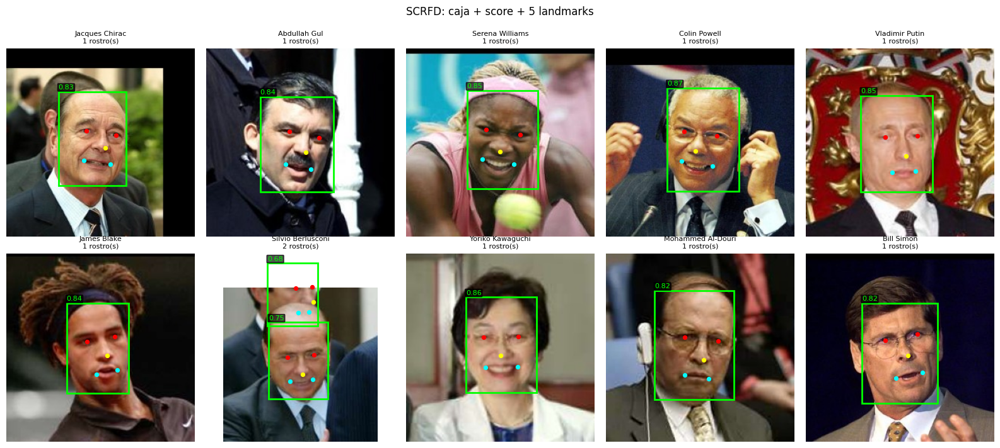

In [ ]:
import matplotlib.patches as mpatches

COLORES_KPS = ['red', 'red', 'yellow', 'cyan', 'cyan']

def dibujar_caras_mpl(ax, img_bgr, caras):
    ax.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    for c in caras:
        x1, y1, x2, y2 = c['bbox']
        ax.add_patch(mpatches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color='lime', linewidth=2))
        ax.text(x1, y1 - 3, f"{c['score']:.2f}", color='lime', fontsize=8,
                bbox=dict(boxstyle='round,pad=0.1', facecolor='black', alpha=0.7))
        if c['kps'] is not None:
            for (lx, ly), col in zip(c['kps'], COLORES_KPS):
                ax.scatter(lx, ly, c=col, s=18, zorder=5)
    ax.axis('off')

muestra = df.sample(10, random_state=SEED)
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for ax, (_, fila) in zip(axes.flat, muestra.iterrows()):
    img = leer_bgr(fila.ruta_raw)
    caras = detectar_rostros(img)
    dibujar_caras_mpl(ax, img, caras)
    ax.set_title(f"{fila.identidad.replace('_', ' ')}\n{len(caras)} rostro(s)", fontsize=8)
plt.suptitle('SCRFD: caja + score + 5 landmarks', y=1.01)
plt.tight_layout()
plt.show()

## 3.5 Detección + alineación sobre todo el dataset

Para cada imagen:
1. Detectamos los rostros y elegimos el **rostro principal** (el más grande y cercano al centro).
2. Lo **alineamos** a 112×112 y lo guardamos en `data/aligned/<identidad>/<archivo>.png` (PNG, para no agregar artefactos de compresión).
3. Medimos todo lo que necesitamos para el control de calidad: tamaño de la caja, nitidez, brillo, contraste, hash perceptual, pose y si hay un segundo rostro.

Las imágenes **no se descartan acá**: solo medimos. Las reglas de descarte están en la sección 4, para poder discutir cada una con ejemplos.
Los resultados se cachean en `metadata_deteccion.pkl`, así que volver a ejecutar la celda es instantáneo.

In [ ]:
def procesar_imagen(ruta_raw):
    """Pipeline completo sobre UNA imagen: leer -> detectar -> rostro principal -> alinear -> medir."""
    p = Path(ruta_raw)
    img = leer_bgr(ruta_raw)
    if img is None:
        return {'corrupto': True, 'n_caras': 0}

    caras = detectar_rostros(img)
    out = {'corrupto': False, 'n_caras': len(caras)}
    if not caras:
        return out

    principal = elegir_rostro_principal(caras, img.shape)
    area_p = area_bbox(principal['bbox'])
    otras = [area_bbox(c['bbox']) for c in caras if c is not principal]
    ratio_segundo = (max(otras) / area_p) if (otras and area_p > 0) else 0.0

    x1, y1, x2, y2 = principal['bbox']
    alineado = alinear_rostro(img, principal['kps'])
    ruta_al = ALIGNED_DIR / p.parent.name / (p.stem + '.png')
    ruta_al.parent.mkdir(parents=True, exist_ok=True)
    cv2.imwrite(str(ruta_al), alineado)

    gris = cv2.cvtColor(alineado, cv2.COLOR_BGR2GRAY)
    out.update({
        'ruta_alineada': str(ruta_al.relative_to(DATA_DIR)),
        'score': principal['score'],
        'bbox': tuple(float(v) for v in principal['bbox']),
        'kps': principal['kps'],
        'lado_bbox': float(min(x2 - x1, y2 - y1)),
        'area_rel': float(area_p / (img.shape[0] * img.shape[1])),
        'ratio_segundo': float(ratio_segundo),
        'roll': angulo_roll(principal['kps']),
        'yaw': yaw_proxy(principal['kps']),
        'lap_var': varianza_laplaciano(gris),
        'brillo_al': float(gris.mean()),
        'contraste_al': float(gris.std()),
        'dhash': dhash_hex(gris),
    })
    return out


CACHE_DET = DATA_DIR / 'metadata_deteccion.pkl'

det = None
if CACHE_DET.exists():
    det = pd.read_pickle(CACHE_DET)
    if det.ruta_raw.tolist() != df.ruta_raw.tolist():
        det = None          # el cache es de otra selección de imágenes: recalculamos

if det is None:
    resultados = [procesar_imagen(r) for r in tqdm(df.ruta_raw, desc='Detección + alineación')]
    det = pd.DataFrame(resultados)
    det.insert(0, 'ruta_raw', df.ruta_raw.values)
    det.to_pickle(CACHE_DET)
    print(f'Resultados guardados en {CACHE_DET.name}')
else:
    print(f'Resultados cargados de {CACHE_DET.name}')

df = pd.concat([df, det.drop(columns='ruta_raw')], axis=1)
df['corrupto'] = df['corrupto'].fillna(False).astype(bool)

print(f'\nRostros detectados por imagen: {dict(sorted(Counter(df.n_caras).items()))}')
print(f'Score medio del rostro principal: {df.score.mean():.3f}')

Resultados cargados de metadata_deteccion.pkl

Rostros detectados por imagen: {0: 6, 1: 3506, 2: 614, 3: 150, 4: 31, 5: 13, 6: 4}
Score medio del rostro principal: 0.838


## 3.6 Antes / después de la alineación

Elegimos las imágenes con **mayor inclinación de cabeza (roll)**, porque ahí es donde más se nota la alineación.
Arriba la imagen original con lo que detectó SCRFD; en el medio un **recorte simple** de la caja redimensionado a 112×112 (lo que haríamos sin alinear); abajo el rostro **alineado**.

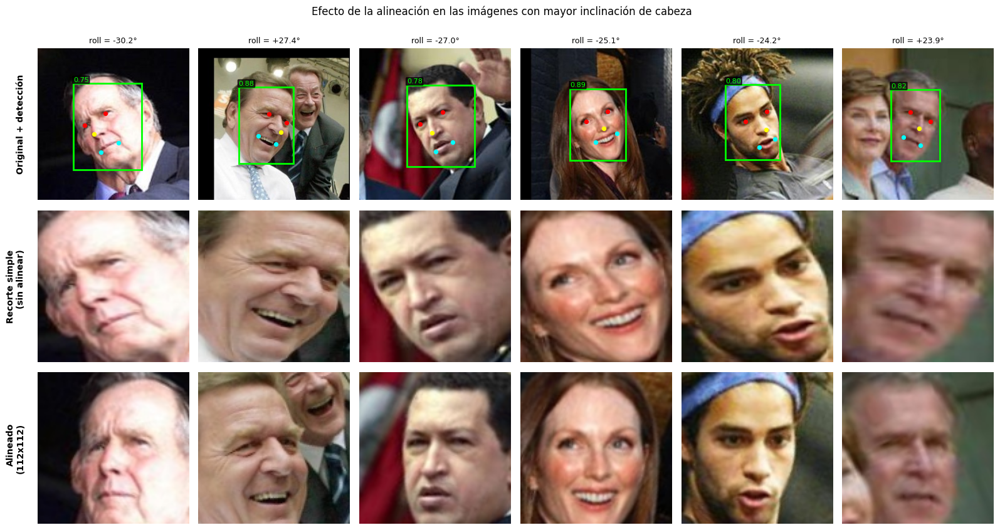

In [ ]:
def recorte_simple(img, bbox, size=FACE_SIZE):
    """Recorte de la caja sin rotar ni escalar con landmarks (baseline 'sin alineación')."""
    h, w = img.shape[:2]
    x1, y1, x2, y2 = [int(round(v)) for v in bbox]
    x1, y1, x2, y2 = max(0, x1), max(0, y1), min(w, x2), min(h, y2)
    return cv2.resize(img[y1:y2, x1:x2], (size, size), interpolation=cv2.INTER_AREA)

con_cara = df[df.n_caras > 0]
extremos = con_cara.reindex(con_cara.roll.abs().sort_values(ascending=False).index).head(6)

fig, axes = plt.subplots(3, 6, figsize=(16, 8.5))
for col, (_, fila) in enumerate(extremos.iterrows()):
    img = leer_bgr(fila.ruta_raw)
    caras = [{'bbox': np.array(fila.bbox), 'score': fila.score, 'kps': fila.kps}]
    dibujar_caras_mpl(axes[0, col], img, caras)
    axes[0, col].set_title(f'roll = {fila.roll:+.1f}°', fontsize=9)

    axes[1, col].imshow(cv2.cvtColor(recorte_simple(img, fila.bbox), cv2.COLOR_BGR2RGB))
    axes[1, col].axis('off')

    axes[2, col].imshow(cv2.cvtColor(leer_bgr(fila.ruta_alineada), cv2.COLOR_BGR2RGB))
    axes[2, col].axis('off')

for fila_i, txt in enumerate(['Original + detección', 'Recorte simple\n(sin alinear)', 'Alineado\n(112x112)']):
    axes[fila_i, 0].text(-0.08, 0.5, txt, transform=axes[fila_i, 0].transAxes,
                         rotation=90, va='center', ha='right', fontsize=10, fontweight='bold')
plt.suptitle('Efecto de la alineación en las imágenes con mayor inclinación de cabeza', y=1.0)
plt.tight_layout()
plt.show()

### Evidencia cuantitativa: la "cara promedio"

Una forma clásica de ver si la alineación funciona es promediar muchas caras: si están bien alineadas, el promedio es **nítido** (ojos, nariz y boca en el mismo lugar);
si no, queda un manchón difuso. Dibujamos encima los 5 puntos de la plantilla de referencia de ArcFace.

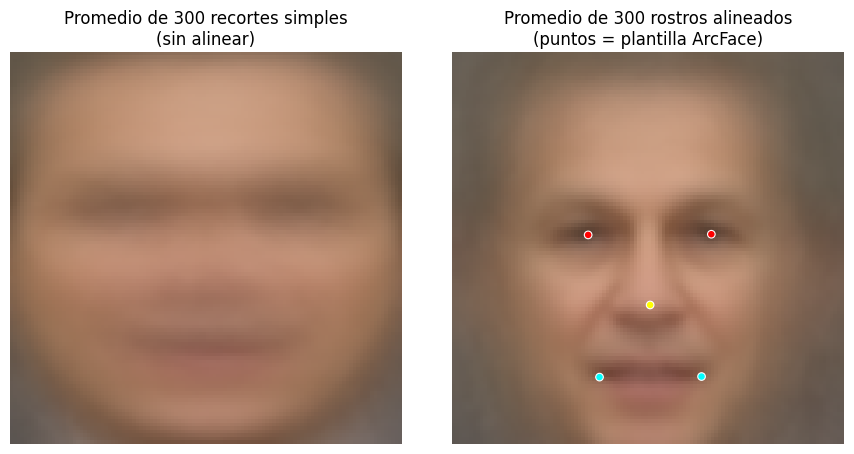

In [ ]:
muestra_prom = con_cara.sample(min(300, len(con_cara)), random_state=SEED)

acum_simple = np.zeros((FACE_SIZE, FACE_SIZE, 3), dtype=np.float64)
acum_alineado = np.zeros((FACE_SIZE, FACE_SIZE, 3), dtype=np.float64)
for _, fila in muestra_prom.iterrows():
    acum_simple += recorte_simple(leer_bgr(fila.ruta_raw), fila.bbox)
    acum_alineado += leer_bgr(fila.ruta_alineada)
prom_simple = (acum_simple / len(muestra_prom)).astype(np.uint8)
prom_alineado = (acum_alineado / len(muestra_prom)).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(cv2.cvtColor(prom_simple, cv2.COLOR_BGR2RGB))
axes[0].set_title(f'Promedio de {len(muestra_prom)} recortes simples\n(sin alinear)')
axes[1].imshow(cv2.cvtColor(prom_alineado, cv2.COLOR_BGR2RGB))
axes[1].scatter(face_align.arcface_dst[:, 0], face_align.arcface_dst[:, 1],
                c=COLORES_KPS, s=30, edgecolors='white', linewidths=0.8)
axes[1].set_title(f'Promedio de {len(muestra_prom)} rostros alineados\n(puntos = plantilla ArcFace)')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

# 4. CONTROL DE CALIDAD

# 4. Control de calidad y limpieza

Nota sobre el orden: el enunciado menciona el control de calidad antes que la detección, pero **varias reglas necesitan el detector** (sin rostro, rostro chico, múltiples rostros),
así que primero detectamos y alineamos (sección 3) y ahora decidimos qué descartar.

## 4.1 ¿Qué nos dice el detector sobre el dataset?

Tamaño del rostro dentro de la imagen, confianza del detector y pose (roll y yaw). Es la otra mitad del EDA: las variaciones de **pose** y **tamaño de rostro**.

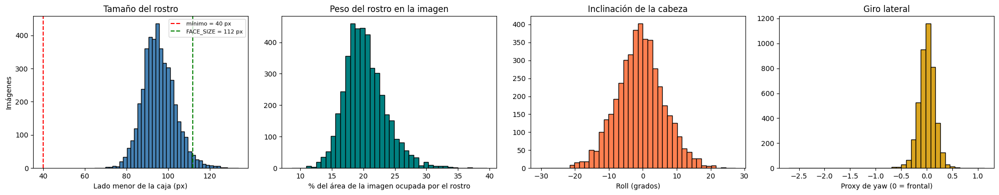

Rostros con lado < FACE_SIZE (112px): 4195 (97.2%) -> se agrandan al alinear (pierden nitidez)
Lado de la caja — mediana: 95px | p5: 84px
|roll| > 15°: 159 imágenes | |yaw| > 0.3: 229 imágenes


In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

axes[0].hist(con_cara.lado_bbox, bins=40, color='steelblue', edgecolor='black')
axes[0].axvline(MIN_FACE_SIZE, color='red', linestyle='--', label=f'mínimo = {MIN_FACE_SIZE} px')
axes[0].axvline(FACE_SIZE, color='green', linestyle='--', label=f'FACE_SIZE = {FACE_SIZE} px')
axes[0].set_xlabel('Lado menor de la caja (px)')
axes[0].set_ylabel('Imágenes')
axes[0].set_title('Tamaño del rostro')
axes[0].legend(fontsize=8)

axes[1].hist(100 * con_cara.area_rel, bins=40, color='teal', edgecolor='black')
axes[1].set_xlabel('% del área de la imagen ocupada por el rostro')
axes[1].set_title('Peso del rostro en la imagen')

axes[2].hist(con_cara.roll, bins=40, color='coral', edgecolor='black')
axes[2].set_xlabel('Roll (grados)')
axes[2].set_title('Inclinación de la cabeza')

axes[3].hist(con_cara.yaw, bins=40, color='goldenrod', edgecolor='black')
axes[3].set_xlabel('Proxy de yaw (0 = frontal)')
axes[3].set_title('Giro lateral')

plt.tight_layout()
plt.show()

n_menores_112 = (con_cara.lado_bbox < FACE_SIZE).sum()
print(f'Rostros con lado < FACE_SIZE ({FACE_SIZE}px): {n_menores_112} ({100 * n_menores_112 / len(con_cara):.1f}%) '
      f'-> se agrandan al alinear (pierden nitidez)')
print(f'Lado de la caja — mediana: {con_cara.lado_bbox.median():.0f}px | p5: {con_cara.lado_bbox.quantile(0.05):.0f}px')
print(f'|roll| > 15°: {(con_cara.roll.abs() > 15).sum()} imágenes | |yaw| > 0.3: {(con_cara.yaw.abs() > 0.3).sum()} imágenes')

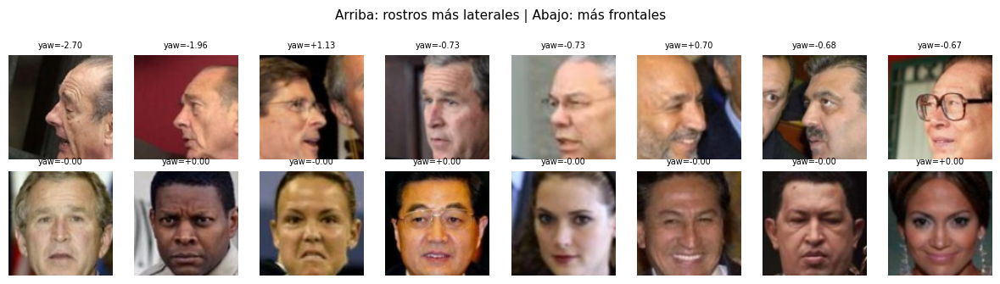

In [ ]:
# Pose: los rostros más laterales vs. los más frontales (ya alineados)
laterales = con_cara.reindex(con_cara.yaw.abs().sort_values(ascending=False).index).head(8)
frontales = con_cara.reindex(con_cara.yaw.abs().sort_values().index).head(8)

imgs = [leer_bgr(r) for r in laterales.ruta_alineada] + [leer_bgr(r) for r in frontales.ruta_alineada]
tits = [f'yaw={y:+.2f}' for y in laterales.yaw] + [f'yaw={y:+.2f}' for y in frontales.yaw]
mostrar_grilla(imgs, tits, ncols=8, titulo='Arriba: rostros más laterales | Abajo: más frontales', lado=1.5, fontsize=7)

## 4.2 Reglas de filtrado

Definimos reglas **explícitas y reproducibles** (los umbrales están en la celda de parámetros) y reportamos cuántas imágenes descarta cada una.

| # | Regla | Criterio | Por qué |
|---|---|---|---|
| 1 | Archivo corrupto | `cv2.imread` devuelve `None` | No se puede usar |
| 2 | Sin rostro | El detector no encuentra ninguno | No hay nada que reconocer |
| 3 | Varios rostros ambiguos | El 2.º rostro tiene ≥ 50% del área del principal | No sabemos de quién es la etiqueta. Si el 2.º es mucho más chico (fondo), nos quedamos con el principal |
| 4 | Rostro chico | Lado menor de la caja < `MIN_FACE_SIZE` (40 px) | Con tan pocos píxeles no hay información de identidad |
| 5 | Borrosa | Varianza del Laplaciano en el 3% más bajo | La nitidez de un rostro es clave para el embedding |
| 6 | Exposición extrema | Brillo medio < 45 o > 210, o contraste < 25 | Rostros quemados o a oscuras |
| 7 | Casi-duplicado | dHash a ≤ 4 bits de otra imagen **de la misma identidad** | Si no, la misma foto cae en train y en test |

La regla de casi-duplicados **por embedding** (similitud > 0.95) necesita embeddings y la aplicamos en la sección 5.

> **Cómo elegimos los umbrales de nitidez y exposición:** no hay un valor universal. Usamos un percentil (nitidez) o valores razonables (exposición) y **validamos mirando imágenes
> a ambos lados del umbral** (sección 4.3). Si se ven mal, se ajusta el parámetro y se vuelve a correr.

In [ ]:
# ── Aplicamos las reglas: cada una agrega una columna booleana ───────────────
LAP_UMBRAL = np.percentile(df.lap_var.dropna(), BLUR_PERCENTIL)

df['r_corrupto'] = df.corrupto
df['r_sin_rostro'] = (df.n_caras == 0) & ~df.corrupto
df['r_multiples'] = df.ratio_segundo >= AMBIGUO_AREA_RATIO
df['r_chico'] = df.lado_bbox < MIN_FACE_SIZE
df['r_borroso'] = df.lap_var < LAP_UMBRAL
df['r_exposicion'] = ((df.brillo_al < BRILLO_MIN) | (df.brillo_al > BRILLO_MAX) | (df.contraste_al < CONTRASTE_MIN))

# ── Regla 7: casi-duplicados por hash perceptual, DENTRO de cada identidad ──
POPCOUNT = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)

def hash_a_bytes(h):
    return np.frombuffer(bytes.fromhex(h), dtype=np.uint8)

def distancias_hamming(h, H):
    """Distancia de Hamming (en bits) entre un hash h (8,) y un conjunto H (N, 8)."""
    return POPCOUNT[np.bitwise_xor(H, h)].sum(axis=1)

REGLAS_PREVIAS = ['r_corrupto', 'r_sin_rostro', 'r_multiples', 'r_chico', 'r_borroso', 'r_exposicion']
df['r_duplicado'] = False
df['dup_de'] = -1                       # índice de la imagen que conservamos

valido = ~df[REGLAS_PREVIAS].any(axis=1)   # solo comparamos entre imágenes que sobreviven a las otras reglas
for ident, g in df[valido].groupby('identidad'):
    idxs = g.index.to_numpy()
    H = np.stack([hash_a_bytes(h) for h in df.loc[idxs, 'dhash']])
    conservadas = []
    for k, idx in enumerate(idxs):
        if conservadas:
            d = distancias_hamming(H[k], H[conservadas])
            j = int(d.argmin())
            if d[j] <= DHASH_MAX_HAMMING:
                df.loc[idx, 'r_duplicado'] = True
                df.loc[idx, 'dup_de'] = idxs[conservadas[j]]
                continue
        conservadas.append(k)

print(f'Umbral de nitidez (percentil {BLUR_PERCENTIL}): varianza del Laplaciano < {LAP_UMBRAL:.1f}')
print('\nImágenes marcadas por cada regla (de forma independiente):')
for col in REGLAS_PREVIAS + ['r_duplicado']:
    print(f'  {col:<16}: {int(df[col].sum()):>5}')

Umbral de nitidez (percentil 3): varianza del Laplaciano < 61.5

Imágenes marcadas por cada regla (de forma independiente):
  r_corrupto      :     0
  r_sin_rostro    :     6
  r_multiples     :   451
  r_chico         :     0
  r_borroso       :   130
  r_exposicion    :    11
  r_duplicado     :    41


## 4.3 Ejemplos de imágenes descartadas por cada regla

Ver qué se descarta es la forma de validar que el umbral tiene sentido.

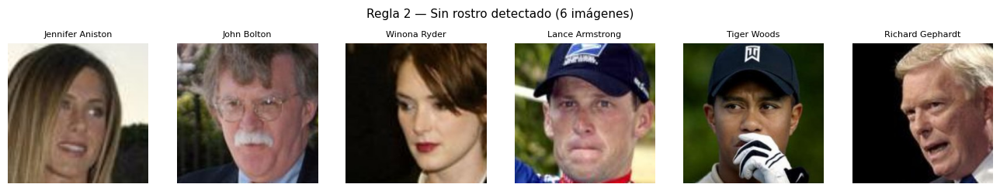

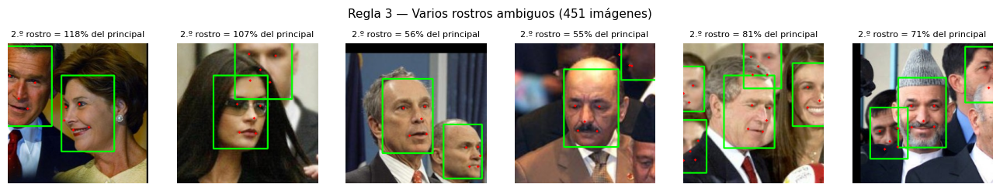

Regla 4: ningún rostro menor a 40px.


In [ ]:
def dibujar_caras_cv(img, caras, color=(0, 255, 0)):
    """Dibuja cajas y landmarks sobre una copia de la imagen (BGR)."""
    out = img.copy()
    for c in caras:
        x1, y1, x2, y2 = [int(v) for v in c['bbox']]
        cv2.rectangle(out, (x1, y1), (x2, y2), color, 2)
        if c['kps'] is not None:
            for (lx, ly) in c['kps']:
                cv2.circle(out, (int(lx), int(ly)), 2, (0, 0, 255), -1)
    return out

def elegir(col, n=6):
    sub = df[df[col]]
    return sub.sample(min(n, len(sub)), random_state=SEED)

# ── Regla 2: sin rostro ──
sub = elegir('r_sin_rostro')
if len(sub):
    mostrar_grilla([leer_bgr(r) for r in sub.ruta_raw], [i.replace('_', ' ') for i in sub.identidad],
                   titulo=f'Regla 2 — Sin rostro detectado ({int(df.r_sin_rostro.sum())} imágenes)', lado=2.2)
else:
    print('Regla 2: ninguna imagen sin rostro.')

# ── Regla 3: varios rostros ambiguos (re-detectamos para dibujar TODAS las cajas) ──
sub = elegir('r_multiples')
if len(sub):
    imgs = []
    for r in sub.ruta_raw:
        img = leer_bgr(r)
        imgs.append(dibujar_caras_cv(img, detectar_rostros(img)))
    mostrar_grilla(imgs, [f'2.º rostro = {x:.0%} del principal' for x in sub.ratio_segundo],
                   titulo=f'Regla 3 — Varios rostros ambiguos ({int(df.r_multiples.sum())} imágenes)', lado=2.2)
else:
    print('Regla 3: ninguna imagen con rostros ambiguos.')

# ── Regla 4: rostro chico ──
sub = elegir('r_chico')
if len(sub):
    imgs = [dibujar_caras_cv(leer_bgr(r.ruta_raw), [{'bbox': r.bbox, 'kps': r.kps}]) for _, r in sub.iterrows()]
    mostrar_grilla(imgs, [f'lado = {x:.0f}px' for x in sub.lado_bbox],
                   titulo=f'Regla 4 — Rostro chico (< {MIN_FACE_SIZE}px) ({int(df.r_chico.sum())} imágenes)', lado=2.2)
else:
    print(f'Regla 4: ningún rostro menor a {MIN_FACE_SIZE}px.')

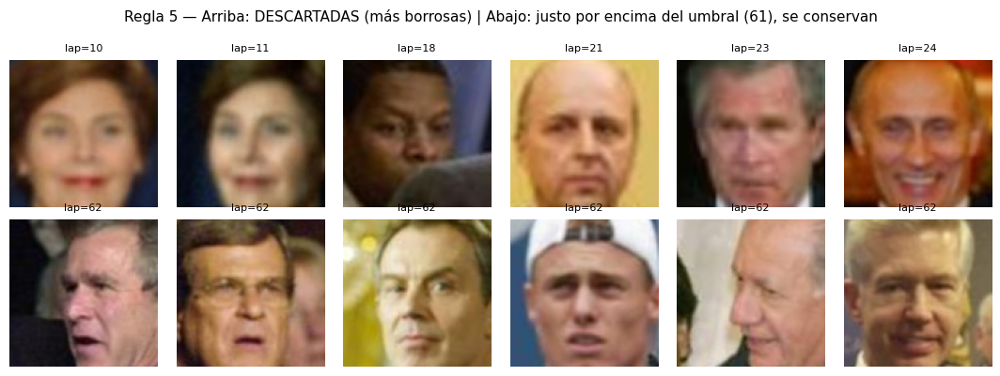

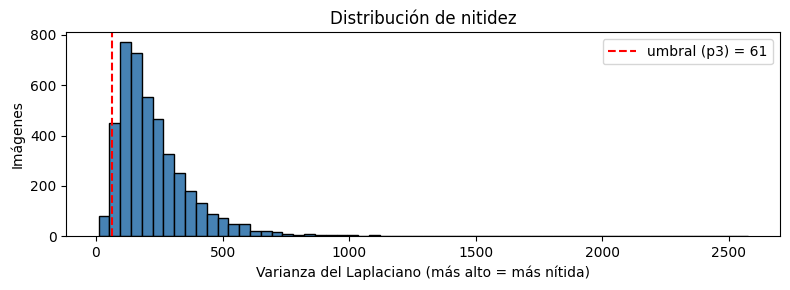

In [ ]:
# ── Regla 5: borrosa. Mostramos las más borrosas (descartadas) y las que quedan justo ARRIBA del umbral (se conservan) ──
con_lap = df[df.lap_var.notna()].sort_values('lap_var')
descartadas = con_lap.head(6)
justo_arriba = con_lap[con_lap.lap_var >= LAP_UMBRAL].head(6)

imgs = [leer_bgr(r) for r in descartadas.ruta_alineada] + [leer_bgr(r) for r in justo_arriba.ruta_alineada]
tits = [f'lap={v:.0f}' for v in descartadas.lap_var] + [f'lap={v:.0f}' for v in justo_arriba.lap_var]
mostrar_grilla(imgs, tits, ncols=6, lado=1.8,
               titulo=f'Regla 5 — Arriba: DESCARTADAS (más borrosas) | Abajo: justo por encima del umbral ({LAP_UMBRAL:.0f}), se conservan')

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(df.lap_var.dropna(), bins=60, color='steelblue', edgecolor='black')
ax.axvline(LAP_UMBRAL, color='red', linestyle='--', label=f'umbral (p{BLUR_PERCENTIL}) = {LAP_UMBRAL:.0f}')
ax.set_xlabel('Varianza del Laplaciano (más alto = más nítida)')
ax.set_ylabel('Imágenes')
ax.set_title('Distribución de nitidez')
ax.legend()
plt.tight_layout()
plt.show()

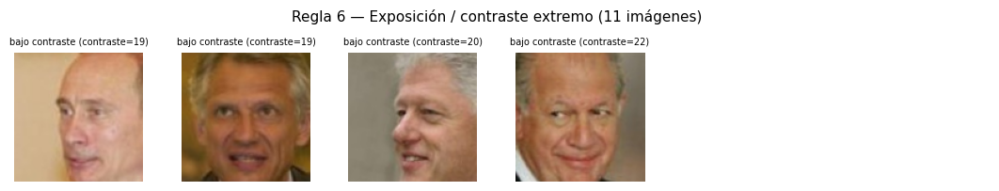

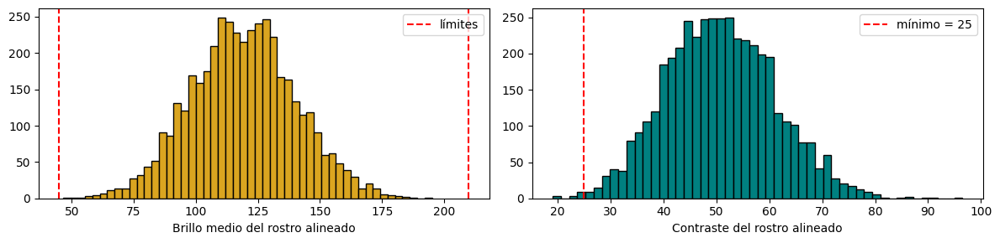

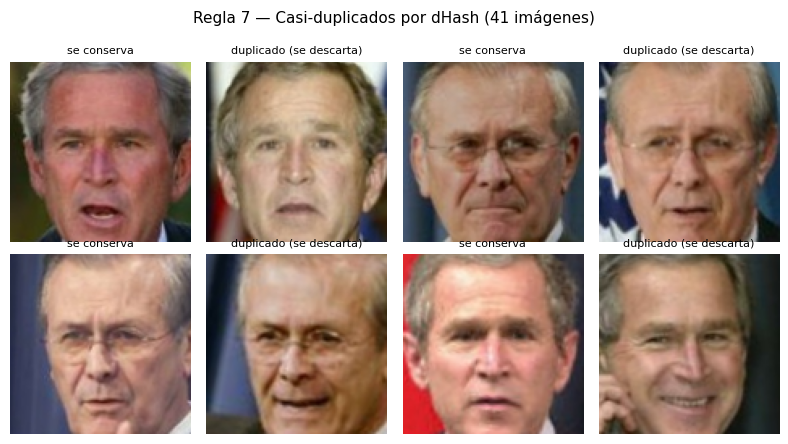

In [ ]:
# ── Regla 6: exposición / contraste ──
oscuras = df[df.brillo_al < BRILLO_MIN].sort_values('brillo_al').head(4)
claras = df[df.brillo_al > BRILLO_MAX].sort_values('brillo_al', ascending=False).head(4)
planas = df[(df.contraste_al < CONTRASTE_MIN) & ~df.index.isin(oscuras.index) & ~df.index.isin(claras.index)] \
    .sort_values('contraste_al').head(4)

grupos = [(oscuras, 'oscura', 'brillo_al'), (claras, 'clara', 'brillo_al'), (planas, 'bajo contraste', 'contraste_al')]
imgs, tits = [], []
for g, nombre, col in grupos:
    for _, r in g.iterrows():
        imgs.append(leer_bgr(r.ruta_alineada))
        tits.append(f'{nombre} ({col[:-3]}={r[col]:.0f})')

if imgs:
    mostrar_grilla(imgs, tits, ncols=6, lado=1.8, fontsize=7,
                   titulo=f'Regla 6 — Exposición / contraste extremo ({int(df.r_exposicion.sum())} imágenes)')
else:
    print('Regla 6: ninguna imagen con exposición extrema.')

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
axes[0].hist(df.brillo_al.dropna(), bins=50, color='goldenrod', edgecolor='black')
axes[0].axvline(BRILLO_MIN, color='red', linestyle='--')
axes[0].axvline(BRILLO_MAX, color='red', linestyle='--', label='límites')
axes[0].set_xlabel('Brillo medio del rostro alineado')
axes[0].legend()
axes[1].hist(df.contraste_al.dropna(), bins=50, color='teal', edgecolor='black')
axes[1].axvline(CONTRASTE_MIN, color='red', linestyle='--', label=f'mínimo = {CONTRASTE_MIN}')
axes[1].set_xlabel('Contraste del rostro alineado')
axes[1].legend()
plt.tight_layout()
plt.show()

# ── Regla 7: duplicados (pares: conservada | descartada) ──
sub = elegir('r_duplicado', n=4)
if len(sub):
    imgs, tits = [], []
    for idx, r in sub.iterrows():
        orig = df.loc[r.dup_de]
        imgs += [leer_bgr(orig.ruta_alineada), leer_bgr(r.ruta_alineada)]
        tits += ['se conserva', 'duplicado (se descarta)']
    mostrar_grilla(imgs, tits, ncols=4, lado=2.0,
                   titulo=f'Regla 7 — Casi-duplicados por dHash ({int(df.r_duplicado.sum())} imágenes)')
else:
    print('Regla 7: no se encontraron casi-duplicados por dHash.')

### ¿Es razonable el umbral de dHash?

Para justificar `DHASH_MAX_HAMMING`, miramos para cada imagen la **distancia (en bits) a su vecino más parecido dentro de la misma identidad**.
Si el umbral está bien puesto, las fotos realmente duplicadas forman un pico a la izquierda (distancia ~0) y **bastante separado** del resto,
y los pares que quedan **justo por encima** del umbral se tienen que ver como fotos distintas.

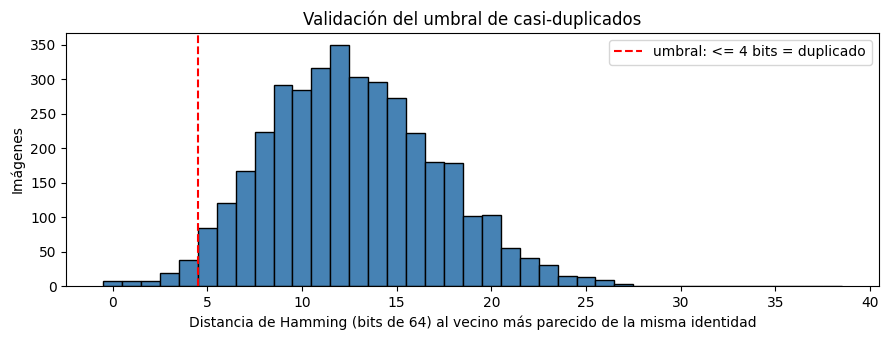

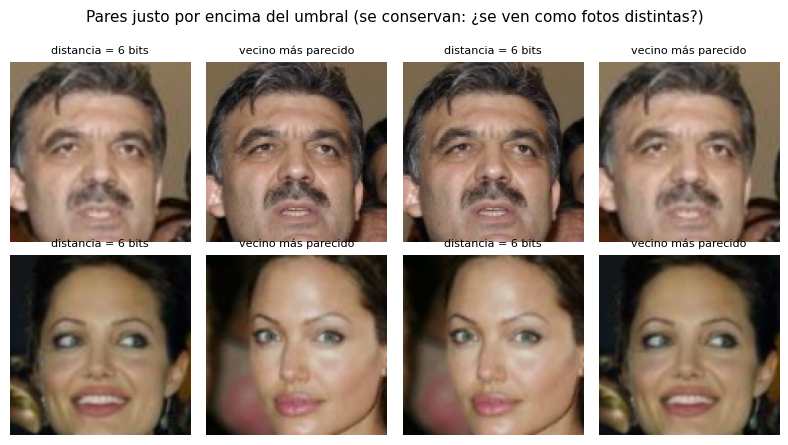

In [ ]:
dist_vecino = pd.Series(np.nan, index=df.index)
vecino_de = pd.Series(-1, index=df.index)
for ident, g in df[valido].groupby('identidad'):
    idxs = g.index.to_numpy()
    H = np.stack([hash_a_bytes(h) for h in df.loc[idxs, 'dhash']])
    for k in range(len(idxs)):
        d = distancias_hamming(H[k], H).astype(int)
        d[k] = 64                                  # no comparar la imagen con ella misma
        j = int(d.argmin())
        dist_vecino[idxs[k]] = d[j]
        vecino_de[idxs[k]] = idxs[j]

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(dist_vecino.dropna(), bins=np.arange(0, 40) - 0.5, color='steelblue', edgecolor='black')
ax.axvline(DHASH_MAX_HAMMING + 0.5, color='red', linestyle='--', label=f'umbral: <= {DHASH_MAX_HAMMING} bits = duplicado')
ax.set_xlabel('Distancia de Hamming (bits de 64) al vecino más parecido de la misma identidad')
ax.set_ylabel('Imágenes')
ax.set_title('Validación del umbral de casi-duplicados')
ax.legend()
plt.tight_layout()
plt.show()

# Pares justo POR ENCIMA del umbral: se conservan, así que tienen que ser fotos distintas
borde = dist_vecino[(dist_vecino > DHASH_MAX_HAMMING) & (dist_vecino <= DHASH_MAX_HAMMING + 2)].index[:4]
if len(borde):
    imgs, tits = [], []
    for i in borde:
        imgs += [leer_bgr(df.loc[i, 'ruta_alineada']), leer_bgr(df.loc[vecino_de[i], 'ruta_alineada'])]
        tits += [f'distancia = {int(dist_vecino[i])} bits', 'vecino más parecido']
    mostrar_grilla(imgs, tits, ncols=4, lado=2.0,
                   titulo='Pares justo por encima del umbral (se conservan: ¿se ven como fotos distintas?)')
else:
    print('No hay pares justo por encima del umbral.')

## 4.4 Resumen: cuántas imágenes descarta cada regla

Hay dos columnas porque una imagen puede incumplir varias reglas a la vez:
- **Marcadas** = cuántas imágenes viola esa regla, sin importar las demás.
- **Descartadas en cascada** = cuántas descarta *realmente* esa regla, aplicándolas en orden (lo que ya cayó por una regla anterior no se cuenta de nuevo).

                     regla  marcadas  descartadas en cascada  % del total  quedan
       1. Archivo corrupto         0                       0         0.00    4324
             2. Sin rostro         6                       6         0.14    4318
3. Varios rostros ambiguos       451                     451        10.43    3867
           4. Rostro chico         0                       0         0.00    3867
                5. Borrosa       130                     114         2.64    3753
     6. Exposición extrema        11                       7         0.16    3746
 7. Casi-duplicado (dHash)        41                      41         0.95    3705


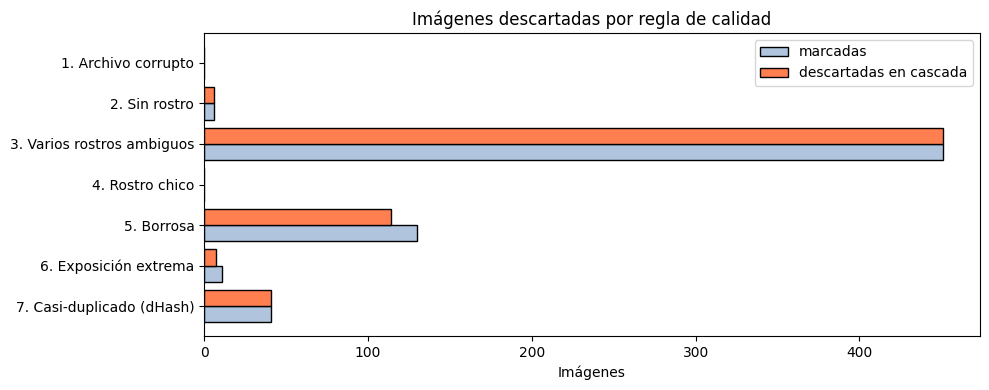

In [ ]:
REGLAS = [
    ('r_corrupto', '1. Archivo corrupto'),
    ('r_sin_rostro', '2. Sin rostro'),
    ('r_multiples', '3. Varios rostros ambiguos'),
    ('r_chico', '4. Rostro chico'),
    ('r_borroso', '5. Borrosa'),
    ('r_exposicion', '6. Exposición extrema'),
    ('r_duplicado', '7. Casi-duplicado (dHash)'),
]

quedan = pd.Series(True, index=df.index)
filas = []
for col, nombre in REGLAS:
    marcadas = int(df[col].sum())
    en_cascada = int((df[col] & quedan).sum())
    quedan &= ~df[col]
    filas.append({'regla': nombre, 'marcadas': marcadas, 'descartadas en cascada': en_cascada,
                  '% del total': round(100 * en_cascada / len(df), 2), 'quedan': int(quedan.sum())})

reporte_calidad = pd.DataFrame(filas)
print(reporte_calidad.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4))
y = np.arange(len(reporte_calidad))
ax.barh(y + 0.2, reporte_calidad['marcadas'], height=0.4, label='marcadas', color='lightsteelblue', edgecolor='black')
ax.barh(y - 0.2, reporte_calidad['descartadas en cascada'], height=0.4, label='descartadas en cascada', color='coral', edgecolor='black')
ax.set_yticks(y)
ax.set_yticklabels(reporte_calidad['regla'])
ax.invert_yaxis()
ax.set_xlabel('Imágenes')
ax.set_title('Imágenes descartadas por regla de calidad')
ax.legend()
plt.tight_layout()
plt.show()

## 4.5 Filtro por identidad

Después de limpiar, hay identidades que pueden haber quedado con pocas imágenes. Volvemos a exigir `MIN_IMGS_FINAL`, porque con menos no se puede partir train/val/test dentro de la identidad.

In [ ]:
registrar_embudo('Tras reglas de calidad (sección 4)', df[quedan])

df_ok = df[quedan].copy()
cuenta = df_ok.groupby('identidad').size()
ids_ok = cuenta[cuenta >= MIN_IMGS_FINAL].index
perdidas = cuenta[cuenta < MIN_IMGS_FINAL]

print(f'Identidades que quedan con < {MIN_IMGS_FINAL} imágenes y se descartan: {len(perdidas)} '
      f'({int(perdidas.sum())} imágenes)')

df_ok = df_ok[df_ok.identidad.isin(ids_ok)].reset_index(drop=True)
registrar_embudo(f'Identidades con >= {MIN_IMGS_FINAL} imágenes limpias', df_ok)
print(f'\nNos quedamos con {df_ok.identidad.nunique()} identidades y {len(df_ok):,} imágenes.')

Identidades que quedan con < 10 imágenes y se descartan: 24 (195 imágenes)

Nos quedamos con 134 identidades y 3,510 imágenes.


### Observaciones del control de calidad

> ✍️ **Completar después de ejecutar:**
> - ¿Qué regla descartó más imágenes? ¿Es lo esperable para LFW?
> - Mirando las grillas, ¿los umbrales de nitidez y exposición descartan imágenes realmente malas? ¿Hay que ajustarlos?
> - ¿Cuántos rostros son más chicos que 112 px (se agrandan al alinear) y qué implica eso para la nitidez del recorte?

# 5. CLUSTERING EXPLORATORIO

# 5. Clustering exploratorio

Usamos clustering como **herramienta de análisis del dataset**, no como gráfico decorativo. Queremos responder:

- ¿Qué tan separables son las identidades en el espacio de embeddings?
- ¿Hay **casi-duplicados** que se nos escaparon con el hash perceptual?
- ¿Hay imágenes **mal etiquetadas** u *outliers* (lejos de su propia clase)?
- ¿Hay **sub-clusters por condiciones de captura** (blanco y negro, perfil)?

Extraemos embeddings con **ArcFace (`w600k_r50`, paquete `buffalo_l`)** sobre los rostros alineados de la sección 4.
Es el mismo modelo que vamos a usar como Modelo B en la notebook 2.

> **Ojo con el sesgo de esta herramienta:** ArcFace fue entrenado con millones de imágenes de internet y no podemos descartar que haya visto algunas identidades de LFW.
> Por eso lo usamos para **diagnosticar el dataset** (detectar duplicados, errores de etiqueta, sub-clusters) y no para sacar conclusiones sobre qué tan bien generaliza un modelo: eso se mide en la notebook 2.

## 5.1 Extracción de embeddings

In [ ]:
CACHE_EMB = DATA_DIR / 'embeddings_buffalo_l.npz'
rutas = df_ok.ruta_alineada.to_numpy().astype(str)

emb = None
if CACHE_EMB.exists():
    z = np.load(CACHE_EMB)
    if np.array_equal(z['rutas'], rutas):
        emb = z['emb']
        print(f'Embeddings cargados de {CACHE_EMB.name}')

if emb is None:
    lotes = []
    for i in tqdm(range(0, len(rutas), 64), desc='Embeddings ArcFace'):
        lotes.append(extraer_embeddings([leer_bgr(r) for r in rutas[i:i + 64]]))
    emb = np.vstack(lotes)
    np.savez(CACHE_EMB, rutas=rutas, emb=emb)

print(f'Embeddings: {emb.shape} | norma L2 media: {np.linalg.norm(emb, axis=1).mean():.4f} (debería ser 1.0)')

Embeddings ArcFace:   0%|          | 0/55 [00:00<?, ?it/s]

Embeddings: (3510, 512) | norma L2 media: 1.0000 (debería ser 1.0)


## 5.2 Casi-duplicados por embedding (regla 7b)

Los embeddings con similitud coseno > `SIM_DUPLICADO` (0.95) son la **misma foto** (o casi).
Distinguimos dos casos:
- **Misma identidad:** duplicado clásico → nos quedamos con una sola.
- **Distinta identidad:** la misma foto aparece con dos etiquetas → es ambigua, descartamos ambas.

Pares con similitud > 0.95: 5
  misma identidad (duplicado): 5
  distinta identidad (misma foto con 2 etiquetas): 0
Imágenes a descartar: 5


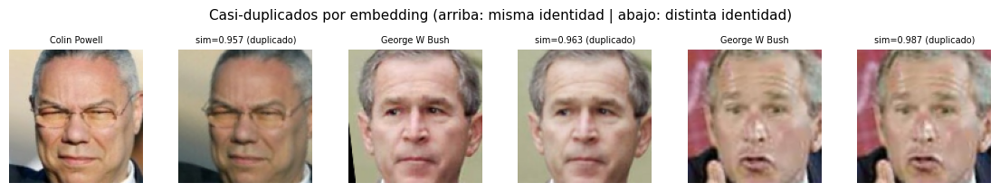


Quedan 3,505 imágenes de 134 identidades.


In [ ]:
S = emb @ emb.T
np.fill_diagonal(S, -1)
ii, jj = np.where(np.triu(S, 1) > SIM_DUPLICADO)

ident_arr = df_ok.identidad.to_numpy()
mismo = ident_arr[ii] == ident_arr[jj]
pares_misma_id = list(zip(ii[mismo], jj[mismo]))
pares_otra_id = list(zip(ii[~mismo], jj[~mismo]))

descartar = set(jj[mismo])
for i, j in pares_otra_id:
    descartar.update([i, j])

print(f'Pares con similitud > {SIM_DUPLICADO}: {len(ii)}')
print(f'  misma identidad (duplicado): {len(pares_misma_id)}')
print(f'  distinta identidad (misma foto con 2 etiquetas): {len(pares_otra_id)}')
print(f'Imágenes a descartar: {len(descartar)}')

# Ejemplos
imgs, tits = [], []
for (i, j) in pares_misma_id[:3]:
    imgs += [leer_bgr(df_ok.ruta_alineada[i]), leer_bgr(df_ok.ruta_alineada[j])]
    tits += [f'{ident_arr[i].replace("_", " ")}', f'sim={S[i, j]:.3f} (duplicado)']
for (i, j) in pares_otra_id[:3]:
    imgs += [leer_bgr(df_ok.ruta_alineada[i]), leer_bgr(df_ok.ruta_alineada[j])]
    tits += [f'{ident_arr[i].replace("_", " ")}', f'{ident_arr[j].replace("_", " ")}\nsim={S[i, j]:.3f}']
if imgs:
    mostrar_grilla(imgs, tits, ncols=6, lado=1.9, fontsize=7,
                   titulo='Casi-duplicados por embedding (arriba: misma identidad | abajo: distinta identidad)')

mantener = np.ones(len(df_ok), dtype=bool)
mantener[list(descartar)] = False
df_ok = df_ok[mantener].reset_index(drop=True)
emb = emb[mantener]
registrar_embudo('Tras casi-duplicados por embedding (5.2)', df_ok)
print(f'\nQuedan {len(df_ok):,} imágenes de {df_ok.identidad.nunique()} identidades.')

## 5.3 Proyección t-SNE

Proyectamos los embeddings (512-d) a 2D con **t-SNE** (distancia coseno). Dos vistas del mismo mapa:
- **Izquierda:** las 12 identidades con más imágenes, cada una de un color. Si el embedding sirve, cada identidad forma su propia isla.
- **Derecha:** coloreado por **condición de captura** (blanco y negro, rostro lateral). Si aparecen islas de un mismo color, hay sub-clusters por condiciones y no por identidad.

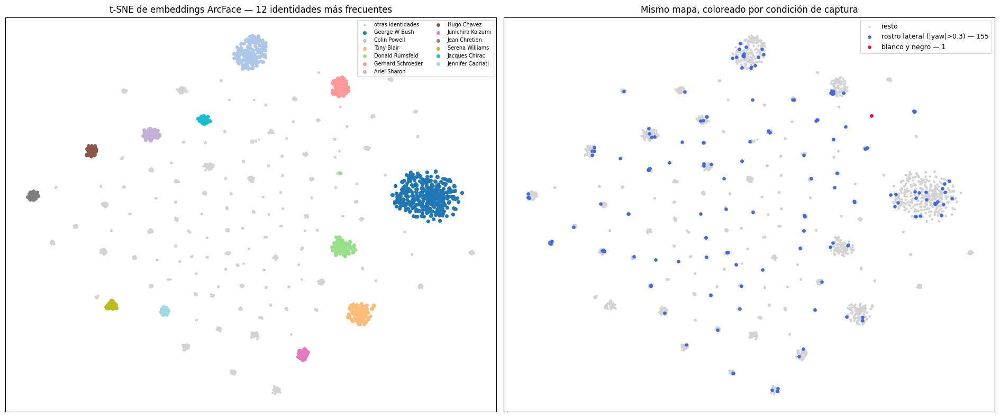

In [ ]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, perplexity=30, init='pca', learning_rate='auto',
            metric='cosine', random_state=SEED)
emb_2d = tsne.fit_transform(emb)

top_ids = df_ok.identidad.value_counts().head(12).index
cmap = plt.cm.tab20(np.linspace(0, 1, 12))

fig, axes = plt.subplots(1, 2, figsize=(19, 8))

ax = axes[0]
ax.scatter(emb_2d[:, 0], emb_2d[:, 1], s=5, color='lightgrey', label='otras identidades')
for k, ident in enumerate(top_ids):
    m = (df_ok.identidad == ident).to_numpy()
    ax.scatter(emb_2d[m, 0], emb_2d[m, 1], s=16, color=cmap[k], label=ident.replace('_', ' '))
ax.legend(fontsize=7, loc='best', ncol=2)
ax.set_title('t-SNE de embeddings ArcFace — 12 identidades más frecuentes')

es_bn = df_ok.es_bn.to_numpy().astype(bool)
lateral = (df_ok.yaw.abs() > 0.3).to_numpy()
ax = axes[1]
ax.scatter(emb_2d[:, 0], emb_2d[:, 1], s=5, color='lightgrey', label='resto')
ax.scatter(emb_2d[lateral, 0], emb_2d[lateral, 1], s=14, color='royalblue', label=f'rostro lateral (|yaw|>0.3) — {lateral.sum()}')
ax.scatter(emb_2d[es_bn, 0], emb_2d[es_bn, 1], s=14, color='crimson', label=f'blanco y negro — {es_bn.sum()}')
ax.legend(fontsize=9)
ax.set_title('Mismo mapa, coloreado por condición de captura')

for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

In [ ]:
# ¿Los sub-clusters por condición son reales? Lo cuantificamos con vecinos más cercanos (k=5):
# si un rostro B/N tiene más vecinos B/N de lo esperable por azar, las B/N se agrupan por condición, no por identidad.
S = emb @ emb.T
np.fill_diagonal(S, -1)
vecinos = np.argpartition(-S, 5, axis=1)[:, :5]

for nombre, flag in [('blanco y negro', es_bn), ('rostro lateral', lateral)]:
    if flag.sum() > 0:
        frac_vecinos = flag[vecinos[flag]].mean()
        print(f'{nombre:<15}: base = {100 * flag.mean():4.1f}% | '
              f'entre los 5 vecinos de una imagen "{nombre}", el {100 * frac_vecinos:4.1f}% también lo es '
              f'(x{frac_vecinos / flag.mean():.1f} sobre el azar)')

## 5.4 Clustering y métricas contra las etiquetas reales

Aplicamos **K-Means** y **clustering aglomerativo** (distancia coseno, enlace promedio) con `k` = cantidad real de identidades y comparamos con las etiquetas:

| Métrica | Qué mide | Rango |
|---|---|---|
| **ARI** (Adjusted Rand Index) | Coincidencia entre clusters y etiquetas, corregida por azar | −1 … 1 (1 = perfecto, ~0 = azar) |
| **NMI** (Normalized Mutual Information) | Información que comparten clusters y etiquetas | 0 … 1 |
| **Silhouette** | Cohesión vs separación. Con las etiquetas reales mide qué tan separables son las identidades | −1 … 1 |

In [ ]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score

def evaluar_clustering(emb, ident):
    """K-Means y aglomerativo con k = cantidad de identidades. Devuelve tabla de métricas y etiquetas de K-Means."""
    y_true, nombres_ids = pd.factorize(ident)
    k = len(nombres_ids)
    km = KMeans(n_clusters=k, n_init=5, random_state=SEED).fit(emb)
    ag = AgglomerativeClustering(n_clusters=k, metric='cosine', linkage='average').fit(emb)
    filas = []
    for nombre, lab in [('K-Means', km.labels_), ('Aglomerativo (coseno, promedio)', ag.labels_)]:
        filas.append({
            'algoritmo': nombre,
            'ARI': adjusted_rand_score(y_true, lab),
            'NMI': normalized_mutual_info_score(y_true, lab),
            'silhouette de los clusters': silhouette_score(emb, lab, metric='cosine'),
        })
    sil_real = silhouette_score(emb, y_true, metric='cosine')
    return pd.DataFrame(filas).round(3), sil_real, km.labels_, y_true, nombres_ids

tabla_antes, sil_real_antes, labels_km, y_true, nombres_ids = evaluar_clustering(emb, df_ok.identidad)
print(f'k = {len(nombres_ids)} identidades | {len(emb)} imágenes\n')
print(tabla_antes.to_string(index=False))
print(f'\nSilhouette con las etiquetas reales de identidad: {sil_real_antes:.3f}')

k = 134 identidades | 3505 imágenes

                      algoritmo   ARI   NMI  silhouette de los clusters
                        K-Means 0.762 0.974                       0.456
Aglomerativo (coseno, promedio) 0.996 0.997                       0.612

Silhouette con las etiquetas reales de identidad: 0.613


### ¿Qué identidades se mezclan o se parten?

Dos diagnósticos con la matriz identidad × cluster de K-Means:
- **Clusters impuros:** mezclan varias identidades → identidades que el modelo confunde.
- **Identidades fragmentadas:** sus imágenes se reparten en varios clusters → fotos con condiciones muy distintas (pose, edad, luz).

Y además miramos qué **pares de identidades** tienen los centroides más parecidos.

In [ ]:
ct = pd.crosstab(df_ok.identidad, labels_km)
pureza = ct.max(axis=0) / ct.sum(axis=0)                  # por cluster: fracción de la identidad mayoritaria
retencion = ct.max(axis=1) / ct.sum(axis=1)               # por identidad: fracción en su cluster principal

print(f'Clusters con pureza >= 90%: {(pureza >= 0.9).sum()} de {len(pureza)}')
print(f'Identidades con >= 80% de sus imágenes en un solo cluster: {(retencion >= 0.8).sum()} de {len(retencion)}')

print('\nClusters más impuros (qué identidades mezclan):')
for c, p in pureza.sort_values().head(6).items():
    comp = ct[c][ct[c] > 0].sort_values(ascending=False).head(3)
    print(f'  cluster {c:>3} (n={ct[c].sum():>3}, pureza={p:.2f}): ' +
          ', '.join(f'{n.replace("_", " ")} ({v})' for n, v in comp.items()))

print('\nIdentidades más fragmentadas (fracción en su cluster principal):')
for n, v in retencion.sort_values().head(6).items():
    print(f'  {n.replace("_", " "):<28}: {v:.2f}  ({ct.loc[n].gt(0).sum()} clusters distintos)')

Clusters con pureza >= 90%: 128 de 134
Identidades con >= 80% de sus imágenes en un solo cluster: 128 de 134

Clusters más impuros (qué identidades mezclan):
  cluster  99 (n= 32, pureza=0.34): Jackie Chan (11), Mahathir Mohamad (11), Kim Ryong-sung (10)
  cluster  50 (n= 36, pureza=0.36): Dominique de Villepin (13), Fidel Castro (12), Mohammad Khatami (10)
  cluster 132 (n= 20, pureza=0.50): Harrison Ford (10), Richard Gere (10)
  cluster  91 (n= 25, pureza=0.52): Nancy Pelosi (13), Hillary Clinton (12)
  cluster 100 (n= 24, pureza=0.58): Kim Clijsters (14), Nicanor Duarte Frutos (10)
  cluster  95 (n= 32, pureza=0.59): Tim Henman (19), Bill Simon (13)

Identidades más fragmentadas (fracción en su cluster principal):
  Gerhard Schroeder           : 0.43  (3 clusters distintos)
  Jean Chretien               : 0.58  (2 clusters distintos)
  George W Bush               : 0.60  (2 clusters distintos)
  Colin Powell                : 0.65  (2 clusters distintos)
  Jeremy Greenstock         

Pares de identidades con centroides más cercanos:
  Serena Williams  <->  Venus Williams: similitud de centroides = 0.426
  Hu Jintao  <->  Wen Jiabao: similitud de centroides = 0.378
  George W Bush  <->  Jeb Bush: similitud de centroides = 0.359
  George HW Bush  <->  George W Bush: similitud de centroides = 0.299


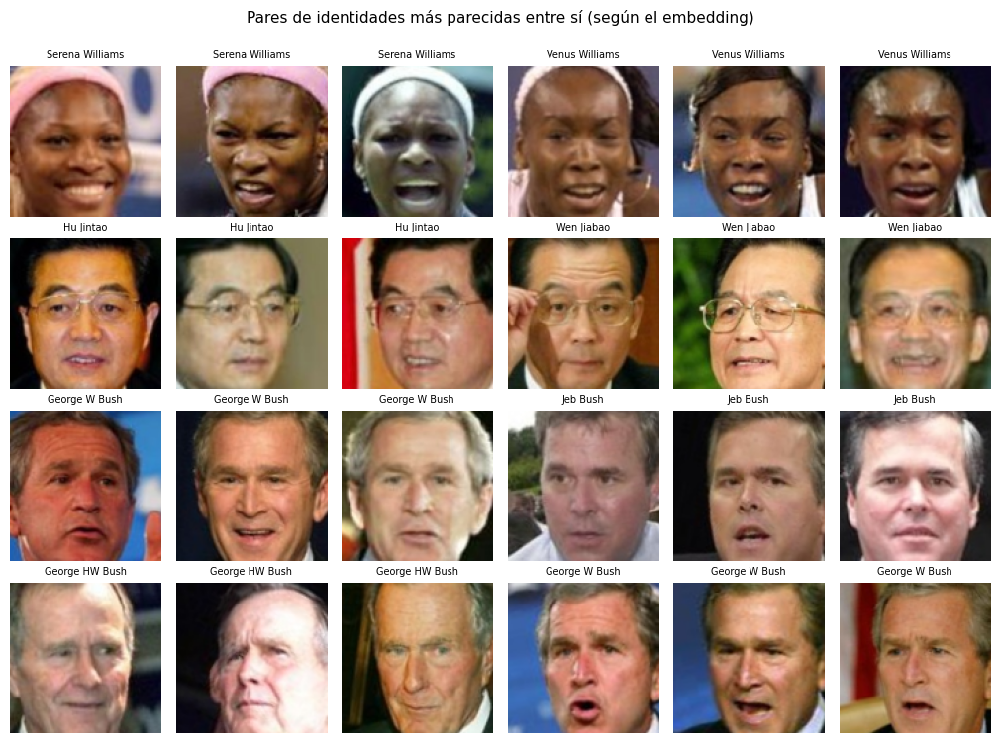

In [ ]:
# Pares de identidades con centroides más parecidos
k_ids = len(nombres_ids)
centroides = np.vstack([emb[y_true == i].mean(axis=0) for i in range(k_ids)])
centroides /= np.linalg.norm(centroides, axis=1, keepdims=True)
Sc = centroides @ centroides.T
np.fill_diagonal(Sc, -1)

orden = np.dstack(np.unravel_index(np.argsort(-Sc.ravel()), Sc.shape))[0]
pares_top, vistos = [], set()
for a, b in orden:
    clave = tuple(sorted((int(a), int(b))))
    if clave not in vistos:
        vistos.add(clave)
        pares_top.append(clave)
    if len(pares_top) == 4:
        break

rng = np.random.default_rng(SEED)
imgs, tits = [], []
print('Pares de identidades con centroides más cercanos:')
for a, b in pares_top:
    print(f'  {nombres_ids[a].replace("_", " ")}  <->  {nombres_ids[b].replace("_", " ")}: similitud de centroides = {Sc[a, b]:.3f}')
    for ident_i in (a, b):
        rutas_i = df_ok.ruta_alineada[y_true == ident_i].to_numpy()
        for r in rng.choice(rutas_i, size=3, replace=False):
            imgs.append(leer_bgr(r))
            tits.append(nombres_ids[ident_i].replace('_', ' '))
mostrar_grilla(imgs, tits, ncols=6, lado=1.7, fontsize=7,
               titulo='Pares de identidades más parecidas entre sí (según el embedding)')

## 5.5 Outliers y posibles errores de etiqueta

Para cada imagen calculamos:
- `sim_propia`: similitud coseno con el **centroide de su propia identidad** calculado **sin esa imagen** (*leave-one-out*, para que la imagen no se "vote" a sí misma).
- `sim_otra`: similitud con el centroide de la **otra identidad más cercana**.

Clasificamos así:
- **Lejana** (`sim_propia < 0.30`): rostro raro respecto de su clase. Puede ser pose extrema, oclusión o edad distinta. **Es difícil pero legítima: la conservamos** (queremos que el modelo vea casos difíciles).
- **Probable error de etiqueta** (lejana **y** `sim_otra > sim_propia`): se parece más a otra persona que a la suya. **La descartamos.**

Imágenes lejanas de su identidad (sim_propia < 0.3): 3
  de ellas, más parecidas a OTRA identidad (probable error de etiqueta): 3


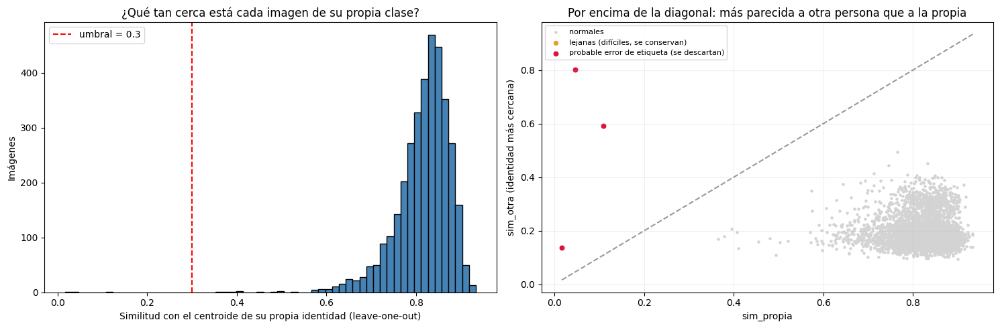

In [ ]:
N = len(emb)
suma_ident = np.vstack([emb[y_true == i].sum(axis=0) for i in range(k_ids)])

# Centroide de la propia identidad SIN la imagen (leave-one-out)
resto = suma_ident[y_true] - emb
resto /= np.linalg.norm(resto, axis=1, keepdims=True)
sim_propia = (emb * resto).sum(axis=1)

# Centroide completo de las demás identidades
cent_full = suma_ident / np.linalg.norm(suma_ident, axis=1, keepdims=True)
sim_a_todas = emb @ cent_full.T
sim_a_todas[np.arange(N), y_true] = -1
otra_id = sim_a_todas.argmax(axis=1)
sim_otra = sim_a_todas.max(axis=1)

df_ok['sim_propia'] = sim_propia
df_ok['sim_otra'] = sim_otra
df_ok['otra_identidad'] = nombres_ids[otra_id]
df_ok['lejana'] = sim_propia < SIM_OUTLIER_PROPIA
df_ok['mal_etiqueta'] = df_ok.lejana & (sim_otra > sim_propia)

print(f'Imágenes lejanas de su identidad (sim_propia < {SIM_OUTLIER_PROPIA}): {int(df_ok.lejana.sum())}')
print(f'  de ellas, más parecidas a OTRA identidad (probable error de etiqueta): {int(df_ok.mal_etiqueta.sum())}')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].hist(sim_propia, bins=60, color='steelblue', edgecolor='black')
axes[0].axvline(SIM_OUTLIER_PROPIA, color='red', linestyle='--', label=f'umbral = {SIM_OUTLIER_PROPIA}')
axes[0].set_xlabel('Similitud con el centroide de su propia identidad (leave-one-out)')
axes[0].set_ylabel('Imágenes')
axes[0].set_title('¿Qué tan cerca está cada imagen de su propia clase?')
axes[0].legend()

normal = ~df_ok.lejana.to_numpy()
axes[1].scatter(sim_propia[normal], sim_otra[normal], s=5, color='lightgrey', label='normales')
axes[1].scatter(sim_propia[df_ok.lejana & ~df_ok.mal_etiqueta], sim_otra[df_ok.lejana & ~df_ok.mal_etiqueta],
                s=18, color='goldenrod', label='lejanas (difíciles, se conservan)')
axes[1].scatter(sim_propia[df_ok.mal_etiqueta], sim_otra[df_ok.mal_etiqueta],
                s=22, color='crimson', label='probable error de etiqueta (se descartan)')
lim = [min(sim_propia.min(), sim_otra.min()), max(sim_propia.max(), sim_otra.max())]
axes[1].plot(lim, lim, 'k--', alpha=0.4)
axes[1].set_xlabel('sim_propia')
axes[1].set_ylabel('sim_otra (identidad más cercana)')
axes[1].set_title('Por encima de la diagonal: más parecida a otra persona que a la propia')
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.2)
plt.tight_layout()
plt.show()

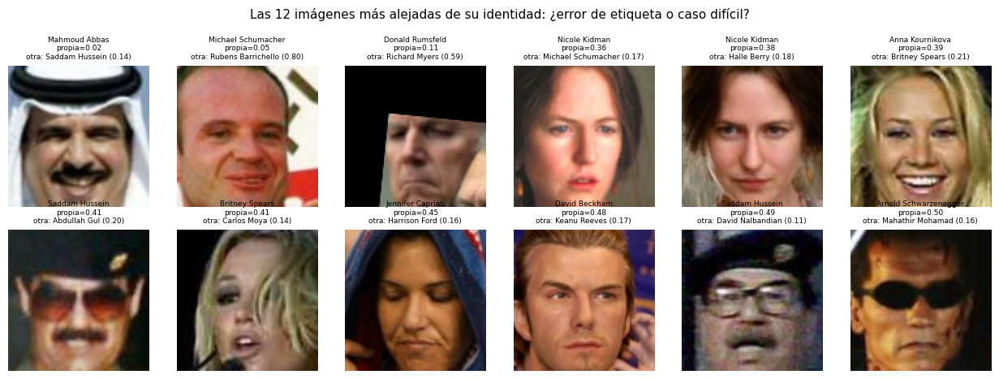

In [ ]:
# Las 12 imágenes más lejanas de su propia identidad, con su etiqueta y la identidad más parecida
peores = df_ok.sort_values('sim_propia').head(12)
imgs = [leer_bgr(r) for r in peores.ruta_alineada]
tits = [f'{r.identidad.replace("_", " ")}\npropia={r.sim_propia:.2f}\notra: {r.otra_identidad.replace("_", " ")} ({r.sim_otra:.2f})'
        for _, r in peores.iterrows()]
mostrar_grilla(imgs, tits, ncols=6, lado=2.1, fontsize=6.5,
               titulo='Las 12 imágenes más alejadas de su identidad: ¿error de etiqueta o caso difícil?')

> ✍️ **Mirar la grilla antes de seguir:** ¿las imágenes marcadas como `mal_etiqueta` son realmente otra persona, o son casos difíciles (perfil, anteojos, otra edad)?
> Si ven que el criterio descarta imágenes legítimas, suban `SIM_OUTLIER_PROPIA` en los parámetros o saquen la condición `sim_otra > sim_propia`.
> Documenten acá qué decidieron.

### Dataset limpio: descartamos los probables errores de etiqueta y recalculamos las métricas

Si la limpieza fue útil, las métricas de clustering deberían **mejorar**.

In [ ]:
keep = ~df_ok.mal_etiqueta.to_numpy()
df_clean = df_ok[keep].reset_index(drop=True)
emb_clean = emb[keep]
registrar_embudo('Tras descartar probables errores de etiqueta (5.5)', df_clean)

# Volvemos a exigir el mínimo de imágenes por identidad
cuenta = df_clean.groupby('identidad').size()
ids_validas = cuenta[cuenta >= MIN_IMGS_FINAL].index
keep2 = df_clean.identidad.isin(ids_validas).to_numpy()
df_clean = df_clean[keep2].reset_index(drop=True)
emb_clean = emb_clean[keep2]
df_clean['idx_emb'] = np.arange(len(df_clean))      # posición de cada imagen en emb_clean
registrar_embudo(f'Identidades con >= {MIN_IMGS_FINAL} imágenes (final)', df_clean)

tabla_despues, sil_real_despues, _, _, _ = evaluar_clustering(emb_clean, df_clean.identidad)

print(f'Dataset limpio: {len(df_clean):,} imágenes | {df_clean.identidad.nunique()} identidades\n')
print('ANTES de descartar errores de etiqueta:')
print(tabla_antes.to_string(index=False))
print('\nDESPUÉS:')
print(tabla_despues.to_string(index=False))
print(f'\nSilhouette con etiquetas reales: antes {sil_real_antes:.3f} -> después {sil_real_despues:.3f}')

Dataset limpio: 3,502 imágenes | 134 identidades

ANTES de descartar errores de etiqueta:
                      algoritmo   ARI   NMI  silhouette de los clusters
                        K-Means 0.762 0.974                       0.456
Aglomerativo (coseno, promedio) 0.996 0.997                       0.612

DESPUÉS:
                      algoritmo   ARI   NMI  silhouette de los clusters
                        K-Means 0.662 0.966                       0.439
Aglomerativo (coseno, promedio) 0.999 0.999                       0.613

Silhouette con etiquetas reales: antes 0.613 -> después 0.614


### Observaciones del clustering

> ✍️ **Completar después de ejecutar:**
> - ¿Las identidades más frecuentes forman islas separadas en el t-SNE? ¿Se mezclan algunas?
> - ¿Aparecen sub-clusters de blanco y negro o de rostros laterales? ¿Qué dice el número de vecinos sobre el azar?
> - ¿Qué pares de identidades se parecen más y por qué podría ser (ámbito, época, rasgos)?
> - ¿Cuántos errores de etiqueta reales encontraron? ¿Mejoraron ARI / NMI después de limpiar?

# 6. DATA AUGMENTATION

# 6. Data augmentation

La augmentation agrega variaciones que **existen en la realidad** (luz, pequeñas poses, desenfoque, oclusiones, compresión) sin cambiar la identidad.
Usamos `albumentations` (ya está en `requirements.txt`) sobre los **rostros alineados de 112×112**.

Reglas que seguimos:
1. **Solo se aplica sobre `train`.** Nunca sobre validación ni test (si no, mediríamos sobre datos modificados).
2. **Se aplica "al vuelo"** en el `DataLoader` de la notebook 2 (cada época ve variantes distintas) en vez de guardar imágenes aumentadas en disco.
3. **Solo transformaciones plausibles:** las que destruyen la identidad o nunca ocurren en una foto real quedan afuera.

## 6.1 Qué incluimos y qué excluimos

| Transformación | Parámetros | Estado | Justificación |
|---|---|---|---|
| Flip horizontal | p = 0.5 | ✅ Incluida | Un rostro espejado sigue siendo plausible; duplica la variedad de pose |
| Affine suave | ±10° rotación, ±5% traslación, escala 0.92–1.08 | ✅ Incluida | Simula pequeños errores de alineación y de encuadre |
| ColorJitter | brillo/contraste ±25%, saturación ±20%, hue ±0.02 | ✅ Incluida | Distintas cámaras e iluminación |
| Blur (gaussiano o de movimiento) | kernel 3–5 | ✅ Incluida | Fotos movidas o fuera de foco |
| Ruido gaussiano | σ 1–5% | ✅ Incluida | Sensores malos, poca luz |
| Compresión JPEG | calidad 40–95 | ✅ Incluida | Las fotos subidas a la app vienen comprimidas |
| Baja resolución (downscale) | escala 0.4–0.8 | ✅ Incluida | Rostros chicos que se agrandan al alinear |
| Coarse dropout | 1 parche de 10–30% | ✅ Incluida | Simula oclusiones (anteojos, barbijo, manos) |
| A escala de grises | p = 0.05 | ✅ Incluida | Hay fotos blanco y negro en el dataset |
| Flip vertical | — | ❌ Excluida | Una cara cabeza abajo no existe en la app |
| Rotación de 90° | — | ❌ Excluida | Ídem; además rompe la alineación |
| Rotación fuerte (±45°) | — | ❌ Excluida | Se aleja de lo que la alineación entrega |
| Distorsión elástica / de grilla | — | ❌ Excluida | Deforma la geometría facial, que es justo lo que codifica la identidad |
| Perspectiva fuerte | — | ❌ Excluida | Ídem |

En 6.3 **medimos** con el embedding de ArcFace cuánto cambia la identidad con cada transformación, para respaldar esta tabla con evidencia.

In [ ]:
import albumentations as A

print(f'albumentations {A.__version__}')

AUG_TRAIN = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.Affine(rotate=(-10, 10), translate_percent=(-0.05, 0.05), scale=(0.92, 1.08),
             border_mode=cv2.BORDER_REFLECT_101, p=0.7),
    A.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.2, hue=0.02, p=0.7),
    A.OneOf([A.GaussianBlur(blur_limit=(3, 5)), A.MotionBlur(blur_limit=(3, 5))], p=0.2),
    A.GaussNoise(std_range=(0.01, 0.05), p=0.2),
    A.ImageCompression(quality_range=(40, 95), p=0.3),
    A.Downscale(scale_range=(0.4, 0.8), p=0.2),
    A.CoarseDropout(num_holes_range=(1, 1), hole_height_range=(0.1, 0.3), hole_width_range=(0.1, 0.3), fill=0, p=0.2),
    A.ToGray(p=0.05),
], seed=SEED)


def aplicar_aug(img_bgr, transform=AUG_TRAIN):
    """Aplica una augmentation a un rostro alineado BGR. Albumentations asume RGB, así que convertimos y volvemos."""
    rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    out = transform(image=rgb)['image']
    return cv2.cvtColor(out, cv2.COLOR_RGB2BGR)


print('Pipeline AUG_TRAIN definido (se usa solo sobre train).')

albumentations 2.0.8
Pipeline AUG_TRAIN definido (se usa solo sobre train).


## 6.2 Ejemplos aumentados de una misma imagen

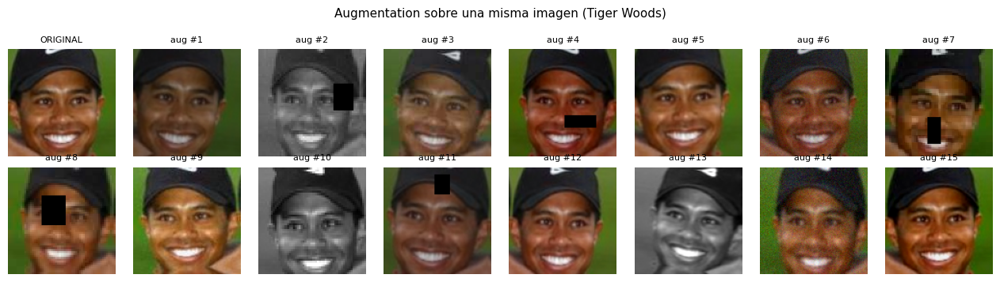

In [ ]:
ejemplo = df_clean.sample(1, random_state=SEED).iloc[0]
base = leer_bgr(ejemplo.ruta_alineada)

imgs = [base] + [aplicar_aug(base) for _ in range(15)]
tits = ['ORIGINAL'] + [f'aug #{i + 1}' for i in range(15)]
mostrar_grilla(imgs, tits, ncols=8, lado=1.6,
               titulo=f'Augmentation sobre una misma imagen ({ejemplo.identidad.replace("_", " ")})')

## 6.3 Evidencia: ¿cuánto cambia la identidad con cada transformación?

Tomamos 150 rostros al azar, les aplicamos **cada transformación por separado** (con p = 1) y medimos la **similitud coseno** entre el embedding original y el del aumentado.
Como referencia marcamos la similitud típica entre **dos fotos distintas de la misma persona** y entre **dos personas distintas**.

- Si una transformación deja la similitud **cerca de 1**, preserva la identidad.
- Si la baja hacia el nivel de "personas distintas", destruye la identidad: no sirve para augmentar.

Evaluando transformaciones:   0%|          | 0/14 [00:00<?, ?it/s]

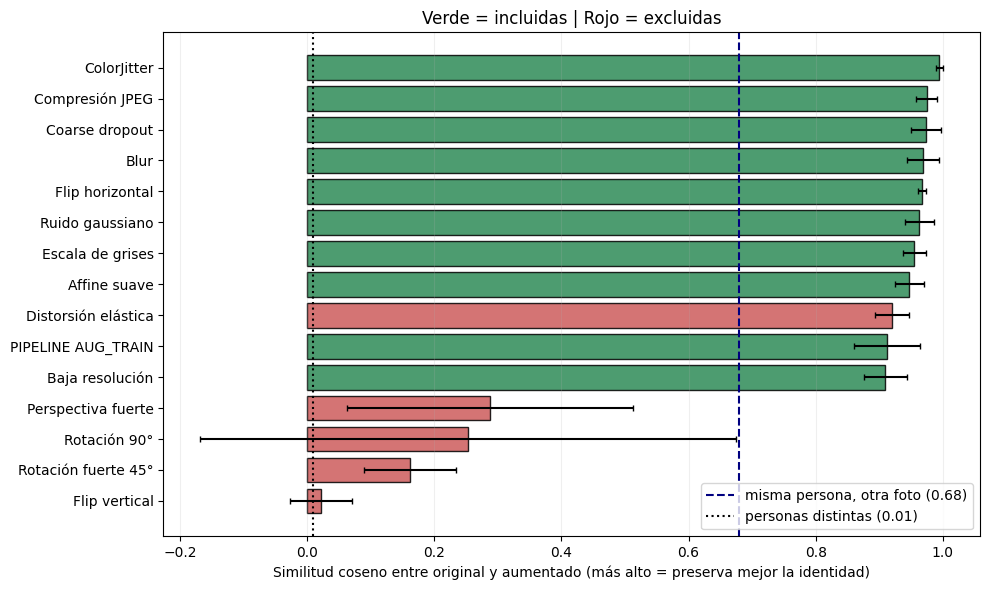

     transformación  incluida  sim_media  sim_std
      Flip vertical     False      0.022    0.049
Rotación fuerte 45°     False      0.162    0.072
       Rotación 90°     False      0.253    0.421
 Perspectiva fuerte     False      0.287    0.225
    Baja resolución      True      0.909    0.034
 PIPELINE AUG_TRAIN      True      0.912    0.052
Distorsión elástica     False      0.920    0.026
       Affine suave      True      0.947    0.022
   Escala de grises      True      0.955    0.018
    Ruido gaussiano      True      0.963    0.022
    Flip horizontal      True      0.968    0.006
               Blur      True      0.969    0.025
     Coarse dropout      True      0.974    0.023
    Compresión JPEG      True      0.975    0.017
        ColorJitter      True      0.994    0.006


In [ ]:
rng = np.random.default_rng(SEED)
idx_eval = rng.choice(len(df_clean), size=min(150, len(df_clean)), replace=False)
originales = [leer_bgr(df_clean.ruta_alineada[i]) for i in idx_eval]
emb_orig = emb_clean[idx_eval]

# (nombre, transformación individual con p=1, ¿la incluimos en el pipeline?)
B = cv2.BORDER_REFLECT_101
CANDIDATAS = [
    ('Flip horizontal',        A.HorizontalFlip(p=1), True),
    ('Affine suave',           A.Affine(rotate=(-10, 10), translate_percent=(-0.05, 0.05), scale=(0.92, 1.08), border_mode=B, p=1), True),
    ('ColorJitter',            A.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.2, hue=0.02, p=1), True),
    ('Blur',                   A.OneOf([A.GaussianBlur(blur_limit=(3, 5)), A.MotionBlur(blur_limit=(3, 5))], p=1), True),
    ('Ruido gaussiano',        A.GaussNoise(std_range=(0.01, 0.05), p=1), True),
    ('Compresión JPEG',        A.ImageCompression(quality_range=(40, 95), p=1), True),
    ('Baja resolución',        A.Downscale(scale_range=(0.4, 0.8), p=1), True),
    ('Coarse dropout',         A.CoarseDropout(num_holes_range=(1, 1), hole_height_range=(0.1, 0.3), hole_width_range=(0.1, 0.3), fill=0, p=1), True),
    ('Escala de grises',       A.ToGray(p=1), True),
    ('Flip vertical',          A.VerticalFlip(p=1), False),
    ('Rotación 90°',           A.RandomRotate90(p=1), False),
    ('Rotación fuerte 45°',    A.Rotate(limit=(45, 45), p=1), False),
    ('Distorsión elástica',    A.ElasticTransform(alpha=120, sigma=12, p=1), False),
    ('Perspectiva fuerte',     A.Perspective(scale=(0.15, 0.25), p=1), False),
]

resultados_aug = []
for nombre, t, incluida in tqdm(CANDIDATAS, desc='Evaluando transformaciones'):
    aug_imgs = [aplicar_aug(im, t) for im in originales]
    sims = (extraer_embeddings(aug_imgs) * emb_orig).sum(axis=1)
    resultados_aug.append({'transformación': nombre, 'incluida': incluida, 'sim_media': sims.mean(), 'sim_std': sims.std()})

# El pipeline completo (con las probabilidades de AUG_TRAIN)
aug_imgs = [aplicar_aug(im) for im in originales]
sims = (extraer_embeddings(aug_imgs) * emb_orig).sum(axis=1)
resultados_aug.append({'transformación': 'PIPELINE AUG_TRAIN', 'incluida': True, 'sim_media': sims.mean(), 'sim_std': sims.std()})

res_aug = pd.DataFrame(resultados_aug).sort_values('sim_media')

# Referencias: misma persona (otra foto) vs personas distintas
ident_clean = df_clean.identidad.to_numpy()
sims_misma, sims_distinta = [], []
for i in idx_eval:
    mismos = np.where((ident_clean == ident_clean[i]) & (np.arange(len(df_clean)) != i))[0]
    otros = np.where(ident_clean != ident_clean[i])[0]
    sims_misma.append(float(emb_clean[i] @ emb_clean[rng.choice(mismos)]))
    sims_distinta.append(float(emb_clean[i] @ emb_clean[rng.choice(otros)]))
ref_misma, ref_distinta = np.mean(sims_misma), np.mean(sims_distinta)

fig, ax = plt.subplots(figsize=(10, 6))
colores = ['seagreen' if inc else 'indianred' for inc in res_aug.incluida]
ax.barh(res_aug['transformación'], res_aug.sim_media, xerr=res_aug.sim_std, color=colores,
        edgecolor='black', alpha=0.85, capsize=2)
ax.axvline(ref_misma, color='navy', linestyle='--', label=f'misma persona, otra foto ({ref_misma:.2f})')
ax.axvline(ref_distinta, color='black', linestyle=':', label=f'personas distintas ({ref_distinta:.2f})')
ax.set_xlabel('Similitud coseno entre original y aumentado (más alto = preserva mejor la identidad)')
ax.set_title('Verde = incluidas | Rojo = excluidas')
ax.legend(loc='lower right')
ax.grid(alpha=0.2, axis='x')
plt.tight_layout()
plt.show()

print(res_aug.round(3).to_string(index=False))

> ✍️ **Interpretar:** ¿las transformaciones excluidas efectivamente caen mucho más cerca del nivel "personas distintas" que las incluidas?
> ¿Hay alguna incluida que baje demasiado la similitud (por ejemplo coarse dropout o baja resolución) y convenga suavizar?

## 6.4 Desbalance de clases: ¿qué hacemos?

| Estrategia | Qué hace | Pro | Contra |
|---|---|---|---|
| **Tope por identidad** (undersampling) | Limita cada identidad a `MAX_IMGS_POR_PERSONA` imágenes | Simple; evita que unas pocas personas dominen el entrenamiento | Descarta datos de las más grandes |
| Oversampling con augmentation | Genera más variantes de las identidades chicas | Usa todos los datos | Hay pocas imágenes base: se puede memorizar |
| *Weighted sampling* / *class weights* | Pondera la frecuencia de muestreo o la loss en entrenamiento | No toca los datos | Las clases chicas se ven muy repetidas |

**Decisión:** aplicamos el **tope por identidad** en la sección 7 (es una decisión sobre los datos) y dejamos el **weighted sampling** como experimento a comparar en la notebook 2.
La augmentation **no** se usa para balancear: se aplica a todas las imágenes de train por igual.

# 7. SPLITS

# 7. Partición de datos (splits)

El enunciado distingue dos escenarios y los dos son importantes para nuestra app:

| Escenario | Pregunta | Cómo se parte | Para qué lo usamos |
|---|---|---|---|
| **Closed-set** (identificación) | ¿Quién es, entre las personas que el modelo vio al entrenar? | Mismas identidades en train y test, **imágenes distintas** (estratificado por identidad) | Monitorear el entrenamiento (val) y medir la clasificación (test_closed) |
| **Open-set** (verificación) | ¿Son la misma persona? ¿Es alguien que no conozco? | **Identidades distintas** en train y test | Es el escenario **real de la app**: se registran personas nuevas |

Armamos **cinco subconjuntos**:

```
Identidades (≈100%)
 ├── 70% → identidades de TRAIN ── imágenes ─┬─ 70% → train        (entrena la CNN)
 │                                            ├─ 15% → val          (early stopping / curvas)
 │                                            └─ 15% → test_closed  (identificación closed-set)
 ├── 15% → identidades NUEVAS ───────────────── val_open   (calibrar el umbral de similitud)
 └── 15% → identidades NUEVAS ───────────────── test_open  (evaluación final open-set)
```

**Por qué dos grupos de identidades nuevas:** el umbral de similitud se calibra en `val_open` y las métricas finales se reportan en `test_open`.
Calibrar el umbral sobre el mismo conjunto donde se reportan las métricas es un error clásico (el enunciado lo marca).

**Por qué 70/15/15:** con pocos cientos de identidades, darle más a test dejaría poco para entrenar y darle menos dejaría pocas identidades nuevas para medir
(las métricas de verificación se vuelven ruidosas con pocas personas). Es un compromiso; lo discutimos en la notebook 2.

## 7.1 Tope por identidad

Para que unas pocas personas muy fotografiadas no dominen el entrenamiento limitamos cada identidad a `MAX_IMGS_POR_PERSONA` imágenes (elegidas al azar con semilla fija).

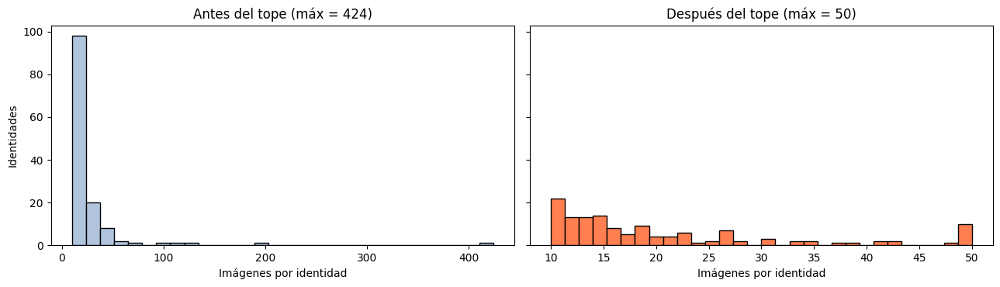

Imágenes: 3,502 -> 2,762 | identidades: 134
Imágenes por identidad — media: 20.6 | mediana: 16 | mín: 10 | máx: 50


In [ ]:
from sklearn.model_selection import train_test_split

cuenta_antes = df_clean.groupby('identidad').size()

df_mezcla = df_clean.sample(frac=1, random_state=SEED)
df_cap = df_mezcla.groupby('identidad').head(MAX_IMGS_POR_PERSONA).sort_index().copy()
cuenta_despues = df_cap.groupby('identidad').size()
registrar_embudo(f'Tras tope de {MAX_IMGS_POR_PERSONA} imágenes por identidad (7.1)', df_cap)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
axes[0].hist(cuenta_antes, bins=30, color='lightsteelblue', edgecolor='black')
axes[0].set_title(f'Antes del tope (máx = {cuenta_antes.max()})')
axes[1].hist(cuenta_despues, bins=30, color='coral', edgecolor='black')
axes[1].set_title(f'Después del tope (máx = {cuenta_despues.max()})')
for ax in axes:
    ax.set_xlabel('Imágenes por identidad')
axes[0].set_ylabel('Identidades')
plt.tight_layout()
plt.show()

print(f'Imágenes: {len(df_clean):,} -> {len(df_cap):,} | identidades: {cuenta_despues.shape[0]}')
print(f'Imágenes por identidad — media: {cuenta_despues.mean():.1f} | mediana: {cuenta_despues.median():.0f} | '
      f'mín: {cuenta_despues.min()} | máx: {cuenta_despues.max()}')

## 7.2 Split por identidad (open-set)

Partimos las **identidades** en train / val_open / test_open. Estratificamos por tercil de cantidad de imágenes para que
cada grupo tenga una mezcla parecida de identidades "grandes" y "chicas" (si no, el azar podría mandar todas las identidades grandes a train).

In [ ]:
cuenta = df_cap.groupby('identidad').size()
terciles = pd.qcut(cuenta.rank(method='first'), q=3, labels=False)      # 0 = pocas imágenes ... 2 = muchas
ids = cuenta.index.to_numpy()

ids_train, ids_resto = train_test_split(
    ids, test_size=1 - PROP_IDS[0], stratify=terciles.loc[ids], random_state=SEED)
ids_val_open, ids_test_open = train_test_split(
    ids_resto, test_size=PROP_IDS[2] / (PROP_IDS[1] + PROP_IDS[2]), stratify=terciles.loc[ids_resto], random_state=SEED)

print(f'Identidades — train: {len(ids_train)} | val_open: {len(ids_val_open)} | test_open: {len(ids_test_open)}')

Identidades — train: 93 | val_open: 20 | test_open: 21


## 7.3 Split por imagen dentro de las identidades de train (closed-set)

Dentro de las identidades de train, partimos las **imágenes** (70/15/15) estratificando por identidad: cada persona queda representada en los tres subconjuntos, con fotos distintas.

In [ ]:
df_ids_train = df_cap[df_cap.identidad.isin(ids_train)]

idx_train, idx_temp = train_test_split(
    df_ids_train.index, test_size=1 - PROP_IMGS[0], stratify=df_ids_train.identidad, random_state=SEED)
idx_val, idx_test_closed = train_test_split(
    idx_temp, test_size=PROP_IMGS[2] / (PROP_IMGS[1] + PROP_IMGS[2]),
    stratify=df_cap.loc[idx_temp, 'identidad'], random_state=SEED)

df_cap['split'] = ''
df_cap.loc[idx_train, 'split'] = 'train'
df_cap.loc[idx_val, 'split'] = 'val'
df_cap.loc[idx_test_closed, 'split'] = 'test_closed'
df_cap.loc[df_cap.identidad.isin(ids_val_open), 'split'] = 'val_open'
df_cap.loc[df_cap.identidad.isin(ids_test_open), 'split'] = 'test_open'
df_cap['escenario'] = df_cap.split.map({'train': 'closed', 'val': 'closed', 'test_closed': 'closed',
                                        'val_open': 'open', 'test_open': 'open'})

assert (df_cap.split != '').all(), 'Hay imágenes sin split asignado'
print(df_cap.split.value_counts().reindex(['train', 'val', 'test_closed', 'val_open', 'test_open']).to_string())

split
train          1289
val             276
test_closed     277
val_open        436
test_open       484


## 7.4 Verificación de ausencia de fuga de datos

Chequeamos cuatro cosas:
1. Las identidades de `val_open` y `test_open` **no aparecen en train** (ni entre sí).
2. Ninguna imagen está en dos splits.
3. Todas las identidades de `val` y `test_closed` están en `train` (closed-set bien armado).
4. **Casi-duplicados entre train y los demás splits** (hash perceptual y embeddings): si la misma foto (recortada distinto) está en train y en test, las métricas salen infladas.

In [ ]:
def chequear(descripcion, ok):
    print(f'  {"OK " if ok else "FALLA"}  {descripcion}')
    return ok

ids_por_split = {s: set(df_cap[df_cap.split == s].identidad) for s in df_cap.split.unique()}

print('Chequeos de identidades e imágenes:')
r1 = chequear('identidades de val_open y test_open disjuntas de train',
              ids_por_split['val_open'].isdisjoint(ids_por_split['train']) and
              ids_por_split['test_open'].isdisjoint(ids_por_split['train']))
r2 = chequear('identidades de val_open y test_open disjuntas entre sí',
              ids_por_split['val_open'].isdisjoint(ids_por_split['test_open']))
r3 = chequear('ninguna imagen repetida entre splits',
              df_cap.ruta_alineada.duplicated().sum() == 0 and df_cap.ruta_raw.duplicated().sum() == 0)
r4 = chequear('val y test_closed solo usan identidades de train',
              ids_por_split['val'] <= ids_por_split['train'] and ids_por_split['test_closed'] <= ids_por_split['train'])

Chequeos de identidades e imágenes:
  OK   identidades de val_open y test_open disjuntas de train
  OK   identidades de val_open y test_open disjuntas entre sí
  OK   ninguna imagen repetida entre splits
  OK   val y test_closed solo usan identidades de train


Imágenes de val/test casi-idénticas a alguna de train: 17


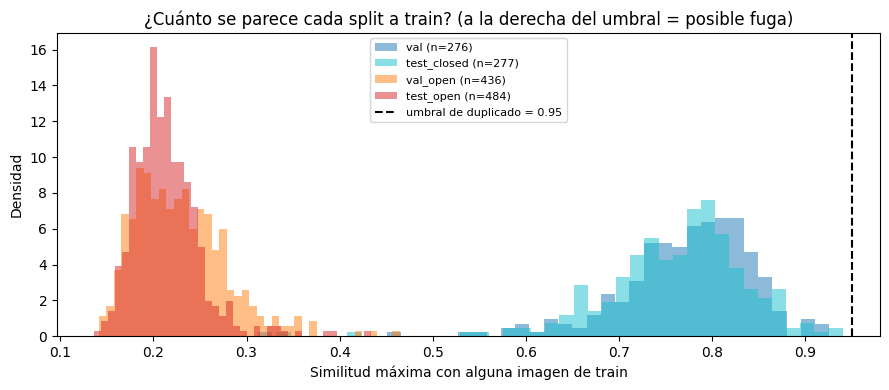

  OK   sin casi-duplicados entre train y val/test

Todos los chequeos OK: True


In [ ]:
def medir_fuga(d):
    """Para cada imagen de val/test: similitud máxima (embedding) y distancia mínima (dHash) contra TRAIN.
    Devuelve (marca_fuga, max_sim, min_ham). 'marca_fuga' es True si es casi-idéntica a alguna imagen de train."""
    H = np.stack([hash_a_bytes(h) for h in d.dhash])
    E = emb_clean[d.idx_emb.to_numpy()]
    pos_train = np.where((d.split == 'train').to_numpy())[0]
    pos_eval = np.where((d.split != 'train').to_numpy())[0]
    max_sim = np.zeros(len(d))
    min_ham = np.full(len(d), 64)
    for p in pos_eval:
        max_sim[p] = (E[pos_train] @ E[p]).max()
        min_ham[p] = distancias_hamming(H[p], H[pos_train]).min()
    marca = np.zeros(len(d), dtype=bool)
    marca[pos_eval] = (max_sim[pos_eval] > SIM_DUPLICADO) | (min_ham[pos_eval] <= DHASH_MAX_HAMMING)
    return marca, max_sim, min_ham


fuga, max_sim, min_ham = medir_fuga(df_cap)
print(f'Imágenes de val/test casi-idénticas a alguna de train: {int(fuga.sum())}')

# Cuánto se parece cada split a train (similitud máxima): el closed-set debería estar más a la derecha que el open-set
fig, ax = plt.subplots(figsize=(9, 4))
for s, c in [('val', 'tab:blue'), ('test_closed', 'tab:cyan'), ('val_open', 'tab:orange'), ('test_open', 'tab:red')]:
    m = (df_cap.split == s).to_numpy()
    ax.hist(max_sim[m], bins=40, alpha=0.5, label=f'{s} (n={m.sum()})', color=c, density=True)
ax.axvline(SIM_DUPLICADO, color='black', linestyle='--', label=f'umbral de duplicado = {SIM_DUPLICADO}')
ax.set_xlabel('Similitud máxima con alguna imagen de train')
ax.set_ylabel('Densidad')
ax.set_title('¿Cuánto se parece cada split a train? (a la derecha del umbral = posible fuga)')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Si hubiera fuga, descartamos esas imágenes de val/test (train no se toca) y volvemos a medir
if fuga.any():
    df_cap = df_cap[~fuga].reset_index(drop=True)
    fuga, _, _ = medir_fuga(df_cap)
else:
    df_cap = df_cap.reset_index(drop=True)

r5 = chequear('sin casi-duplicados entre train y val/test', int(fuga.sum()) == 0)
print(f'\nTodos los chequeos OK: {all([r1, r2, r3, r4, r5])}')
registrar_embudo('Dataset final (tras chequeo de fuga)', df_cap)

## 7.5 Guardado de los splits

Guardamos un **CSV con rutas y etiquetas** (y algunas métricas de calidad útiles para el análisis de errores), el mapa de etiquetas de las identidades de train y la tabla de calidad.
La notebook 2 solo tiene que leer estos archivos: no re-procesa nada y usa **exactamente los mismos splits**.

In [ ]:
# Etiqueta numérica solo para las identidades de train (las demás son "nuevas": label = -1)
label_map = {ident: i for i, ident in enumerate(sorted(ids_train))}
df_cap['label'] = df_cap.identidad.map(label_map).fillna(-1).astype(int)

columnas = ['ruta_raw', 'ruta_alineada', 'identidad', 'label', 'split', 'escenario',
            'score', 'lado_bbox', 'lap_var', 'brillo_al', 'contraste_al', 'es_bn', 'roll', 'yaw']
splits = df_cap[columnas].sort_values(['split', 'identidad', 'ruta_raw']).reset_index(drop=True)

splits.to_csv(SPLITS_DIR / 'splits.csv', index=False)
with open(SPLITS_DIR / 'label_map.json', 'w', encoding='utf-8') as f:
    json.dump(label_map, f, ensure_ascii=False, indent=2)
reporte_calidad.to_csv(SPLITS_DIR / 'reporte_calidad.csv', index=False)

print(f'Guardado en {SPLITS_DIR.resolve()}:')
for f in sorted(SPLITS_DIR.iterdir()):
    print(f'  {f.name:<22} {f.stat().st_size / 1024:8.1f} KB')

Guardado en /content/drive/MyDrive/tp1_reconocimiento_facial/data/splits:
  label_map.json              2.2 KB
  reporte_calidad.csv         0.3 KB
  splits.csv                693.4 KB


# 8. ÉTICA

# 8. Ética, privacidad y licencias

Los rostros son **datos biométricos**: permiten identificar de forma unívoca a una persona y no se pueden "cambiar" si se filtran, como una contraseña.
Por eso conviene tratarlos con más cuidado que a otros datos.

**Licencia y uso permitido**
- **LFW:** se distribuye para investigación y evaluación académica. Las fotos son de figuras públicas tomadas de noticias y **conservan el copyright de sus fuentes originales**.
  Las usamos únicamente con fines académicos en este trabajo y **no las redistribuimos**: `data/*` está excluido del repositorio (`.gitignore`).
- **Modelos de InsightFace** (SCRFD y ArcFace `buffalo_l`): los pesos preentrenados son de uso **no comercial / investigación**. No se pueden usar tal cual en un producto comercial.
- **Fotos propias:** no usamos. Si el grupo suma fotos de amigos o familia, hace falta **consentimiento informado y explícito** de cada persona y no se suben al repositorio.

**Sesgos del dataset y su impacto**
- LFW tiene una **fuerte mayoría de varones y de personas de piel clara**, y son personas públicas de una época y un ámbito acotados (política, deporte, espectáculos).
- Los sistemas de reconocimiento facial suelen rendir **peor en mujeres, personas mayores y personas de piel oscura** cuando se entrenan con datos así. Esto puede traducirse en **más falsos positivos** (confundir a dos personas distintas) o **más falsos negativos** en esos grupos.
- Por eso los resultados de este trabajo **no deben extrapolarse** a poblaciones distintas a la del dataset sin volver a medir.

**Marco legal (Argentina)**
- La **Ley 25.326 de Protección de Datos Personales** exige que los datos personales se usen para una finalidad determinada (art. 4) y con el **consentimiento libre, expreso e informado** del titular (art. 5).
  Una app como la nuestra, que guarda embeddings asociados a una identidad, tendría que cumplir con eso: informar qué se guarda, para qué, y permitir borrarlo.
- Los embeddings **también son datos personales**: aunque no sean una imagen, permiten reconocer a la persona.

**Riesgos del reconocimiento facial** (para tener en cuenta más allá del TP): vigilancia masiva, identificaciones erróneas con consecuencias graves, uso sin consentimiento y falta de transparencia sobre el desempeño por grupos.
Esta app es un **trabajo académico** y no debe usarse para decisiones que afecten a personas reales.

# 9. RESUMEN

# 9. Resumen final

## 9.1 Embudo del dataset: de LFW completo al dataset final

Cuántas identidades e imágenes quedan después de cada etapa.

                                             etapa  identidades  imágenes  imágenes descartadas
                                      LFW completo         5749     13233                     0
                    Identidades con >= 10 imágenes          158      4324                  8909
                Tras reglas de calidad (sección 4)          158      3705                   619
            Identidades con >= 10 imágenes limpias          134      3510                   195
          Tras casi-duplicados por embedding (5.2)          134      3505                     5
Tras descartar probables errores de etiqueta (5.5)          134      3502                     3
            Identidades con >= 10 imágenes (final)          134      3502                     0
      Tras tope de 50 imágenes por identidad (7.1)          134      2762                   740
              Dataset final (tras chequeo de fuga)          134      2745                    17


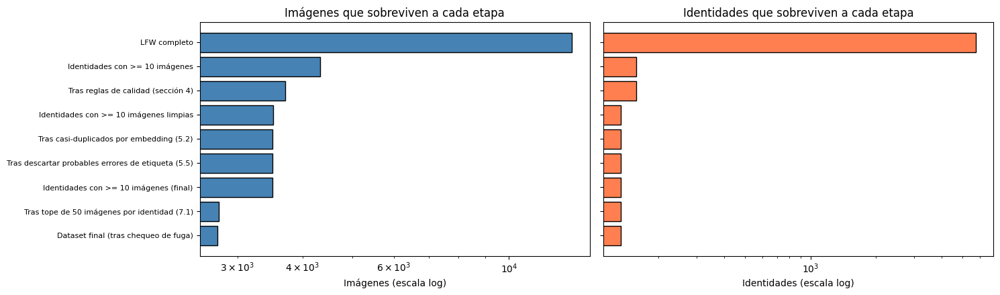

In [ ]:
embudo = pd.DataFrame(EMBUDO)
embudo['imágenes descartadas'] = (-embudo['imágenes'].diff()).fillna(0).astype(int)
print(embudo.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
y = np.arange(len(embudo))
axes[0].barh(y, embudo['imágenes'], color='steelblue', edgecolor='black')
axes[0].set_yticks(y); axes[0].set_yticklabels(embudo['etapa'], fontsize=8)
axes[0].invert_yaxis(); axes[0].set_xscale('log')
axes[0].set_xlabel('Imágenes (escala log)'); axes[0].set_title('Imágenes que sobreviven a cada etapa')
axes[1].barh(y, embudo['identidades'], color='coral', edgecolor='black')
axes[1].set_yticks(y); axes[1].set_yticklabels([])
axes[1].invert_yaxis(); axes[1].set_xscale('log')
axes[1].set_xlabel('Identidades (escala log)'); axes[1].set_title('Identidades que sobreviven a cada etapa')
plt.tight_layout()
plt.show()

## 9.2 Tabla resumen por split

      split escenario  identidades  imágenes  % imágenes imgs/identidad (mín / mediana / máx)
      train    closed           93      1289        47.0                          7 / 11 / 35
        val    closed           93       272         9.9                            1 / 2 / 7
test_closed    closed           93       276        10.1                            1 / 2 / 8
   val_open      open           20       431        15.7                         10 / 17 / 50
  test_open      open           21       477        17.4                         11 / 19 / 50

TOTAL: 2,745 imágenes | 134 identidades (93 de train + 20 val_open + 21 test_open)


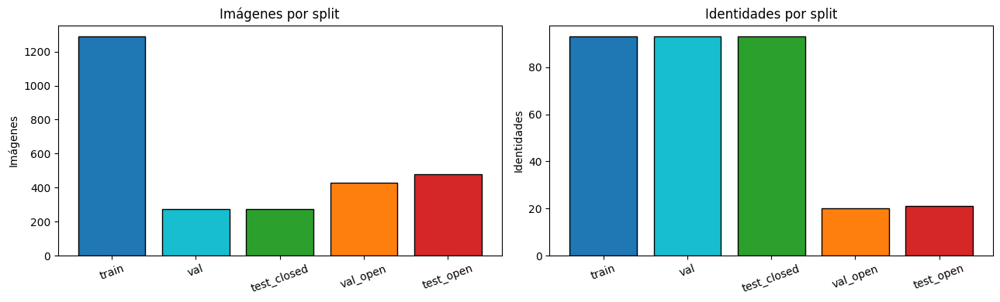

In [ ]:
orden_splits = ['train', 'val', 'test_closed', 'val_open', 'test_open']
resumen = []
for s in orden_splits:
    d = splits[splits.split == s]
    por_id = d.groupby('identidad').size()
    resumen.append({
        'split': s,
        'escenario': d.escenario.iloc[0],
        'identidades': d.identidad.nunique(),
        'imágenes': len(d),
        '% imágenes': round(100 * len(d) / len(splits), 1),
        'imgs/identidad (mín / mediana / máx)': f'{por_id.min()} / {por_id.median():.0f} / {por_id.max()}',
    })
tabla_resumen = pd.DataFrame(resumen)
print(tabla_resumen.to_string(index=False))
print(f'\nTOTAL: {len(splits):,} imágenes | {splits.identidad.nunique()} identidades '
      f'({len(ids_train)} de train + {len(ids_val_open)} val_open + {len(ids_test_open)} test_open)')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
colores_split = ['tab:blue', 'tab:cyan', 'tab:green', 'tab:orange', 'tab:red']
axes[0].bar(tabla_resumen.split, tabla_resumen['imágenes'], color=colores_split, edgecolor='black')
axes[0].set_ylabel('Imágenes'); axes[0].set_title('Imágenes por split')
axes[1].bar(tabla_resumen.split, tabla_resumen['identidades'], color=colores_split, edgecolor='black')
axes[1].set_ylabel('Identidades'); axes[1].set_title('Identidades por split')
for ax in axes:
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

## 9.3 Configuración guardada para la notebook 2 y la app

Guardamos todos los parámetros del preprocesamiento en `config_preprocesamiento.json`. Los valores que van al `.env` de la app están marcados.

In [ ]:
import importlib.metadata as md_

def version(pkg):
    try:
        return md_.version(pkg)
    except Exception:
        return 'n/d'

CONFIG = {
    'seed': SEED,
    'pipeline': {
        'detector': 'SCRFD (buffalo_l / det_10g)',
        'alineacion': 'insightface.utils.face_align.norm_crop (similitud 5 landmarks -> plantilla ArcFace)',
        'orden_canales': 'BGR',
        'tipo_imagen': 'uint8',
        'FACE_SIZE': FACE_SIZE,                      # .env
        'DET_SCORE_THRESHOLD': DET_SCORE_THRESHOLD,  # .env
        'DET_INPUT_SIZE': list(DET_INPUT_SIZE),      # .env
        'MIN_FACE_SIZE': MIN_FACE_SIZE,              # .env
        'rostro_principal': 'mayor area x cercania al centro',
    },
    'calidad': {
        'AMBIGUO_AREA_RATIO': AMBIGUO_AREA_RATIO,
        'BLUR_PERCENTIL': BLUR_PERCENTIL,
        'LAP_UMBRAL': round(float(LAP_UMBRAL), 3),
        'BRILLO_MIN': BRILLO_MIN, 'BRILLO_MAX': BRILLO_MAX, 'CONTRASTE_MIN': CONTRASTE_MIN,
        'DHASH_MAX_HAMMING': DHASH_MAX_HAMMING, 'SIM_DUPLICADO': SIM_DUPLICADO,
        'SIM_OUTLIER_PROPIA': SIM_OUTLIER_PROPIA,
    },
    'dataset': {
        'fuente': 'LFW (lfw.tgz, version sin funneled)',
        'MIN_IMGS_CARGA': MIN_IMGS_CARGA, 'MIN_IMGS_FINAL': MIN_IMGS_FINAL,
        'MAX_IMGS_POR_PERSONA': MAX_IMGS_POR_PERSONA,
        'PROP_IDS': list(PROP_IDS), 'PROP_IMGS': list(PROP_IMGS),
        'identidades_finales': int(splits.identidad.nunique()),
        'imagenes_finales': int(len(splits)),
    },
    'versiones': {p: version(p) for p in ['insightface', 'onnxruntime', 'albumentations', 'opencv-python-headless',
                                           'opencv-python', 'scikit-learn', 'numpy', 'pandas']},
}

with open(SPLITS_DIR / 'config_preprocesamiento.json', 'w', encoding='utf-8') as f:
    json.dump(CONFIG, f, ensure_ascii=False, indent=2)
print(json.dumps(CONFIG, ensure_ascii=False, indent=2))

{
  "seed": 42,
  "pipeline": {
    "detector": "SCRFD (buffalo_l / det_10g)",
    "alineacion": "insightface.utils.face_align.norm_crop (similitud 5 landmarks -> plantilla ArcFace)",
    "orden_canales": "BGR",
    "tipo_imagen": "uint8",
    "FACE_SIZE": 112,
    "DET_SCORE_THRESHOLD": 0.5,
    "DET_INPUT_SIZE": [
      640,
      640
    ],
    "MIN_FACE_SIZE": 40,
    "rostro_principal": "mayor area x cercania al centro"
  },
  "calidad": {
    "AMBIGUO_AREA_RATIO": 0.5,
    "BLUR_PERCENTIL": 3,
    "LAP_UMBRAL": 61.486,
    "BRILLO_MIN": 45,
    "BRILLO_MAX": 210,
    "CONTRASTE_MIN": 25,
    "DHASH_MAX_HAMMING": 4,
    "SIM_DUPLICADO": 0.95,
    "SIM_OUTLIER_PROPIA": 0.3
  },
  "dataset": {
    "fuente": "LFW (lfw.tgz, version sin funneled)",
    "MIN_IMGS_CARGA": 10,
    "MIN_IMGS_FINAL": 10,
    "MAX_IMGS_POR_PERSONA": 50,
    "PROP_IDS": [
      0.7,
      0.15,
      0.15
    ],
    "PROP_IMGS": [
      0.7,
      0.15,
      0.15
    ],
    "identidades_finales": 134,
    "i

## 9.4 Cómo usar los splits desde `2-train.ipynb`

La notebook 2 no vuelve a procesar nada: lee `splits.csv` y carga los rostros ya alineados (BGR 112×112).

Imágenes por split: {'train': 1289, 'test_open': 477, 'val_open': 431, 'test_closed': 276, 'val': 272}


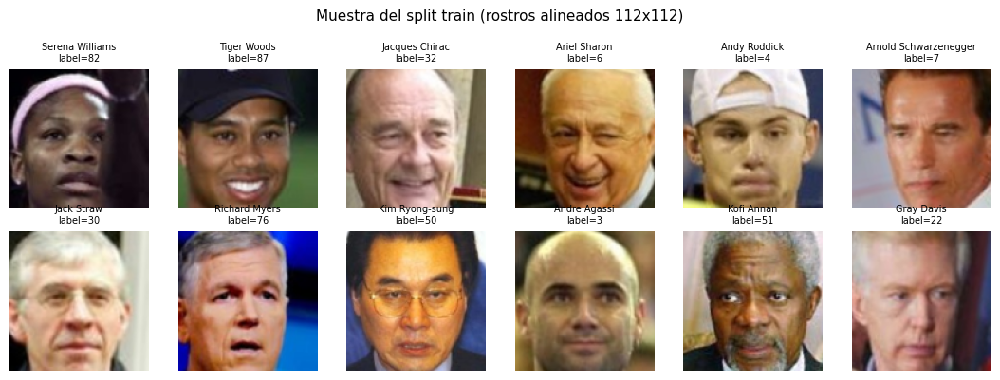

In [ ]:
# ── Así se cargan los splits en la notebook 2 ────────────────────────────────
splits_nb2 = pd.read_csv(SPLITS_DIR / 'splits.csv')
train_nb2 = splits_nb2[splits_nb2.split == 'train']

print('Imágenes por split:', splits_nb2.split.value_counts().to_dict())

# Los rostros alineados son BGR uint8 de 112x112 (igual que lo que va a recibir la app)
ejemplos_train = train_nb2.sample(12, random_state=SEED)
mostrar_grilla([leer_bgr(r) for r in ejemplos_train.ruta_alineada],
               [f'{i.replace("_", " ")}\nlabel={l}' for i, l in zip(ejemplos_train.identidad, ejemplos_train.label)],
               ncols=6, lado=1.8, fontsize=7, titulo='Muestra del split train (rostros alineados 112x112)')

## 9.5 Checklist de la notebook 1 (ENUNCIADO 2.9)

| Salida esperada | Dónde está |
|---|---|
| Justificación del dataset y limitaciones | Sección 1 |
| EDA: distribución de clases, resoluciones, ejemplos y variaciones | Secciones 2 y 4.1 |
| Reglas de calidad con cantidad de descartes y ejemplos | Sección 4 |
| Pipeline de detección + alineación con antes/después | Sección 3 |
| Clustering exploratorio con interpretación | Sección 5 |
| Pipeline de augmentation justificado y visualizado | Sección 6 |
| Splits guardados y verificación de ausencia de fuga | Sección 7 |
| Tabla resumen: identidades e imágenes por split | Sección 9.2 |
| Ética y licencias | Sección 8 |

## Próximos pasos

1. **Pasar el pipeline a un módulo** (por ejemplo `src/lib/preprocessing.py`) con `detectar_rostros`, `alinear_rostro`, `kps_relativos` y `extraer_embeddings`, e importarlo desde las notebooks y desde `face_service.py`.
2. **`2-train.ipynb`:** leer `splits.csv`, entrenar la CNN custom con `AUG_TRAIN` solo sobre `train`, y evaluar ambos modelos sobre `test_closed` y `test_open` (calibrando el umbral en `val_open`).
3. **Completar las celdas ✍️** de observaciones con lo que muestran los gráficos de su ejecución, y completar la celda *Equipo*.